| Step | What | Output |
|---|---|---|
| A1 | Load the raw reviews, check it is the expected dataset | |
| A2 | Clean the text, correct the condition names of this dataset | |
| A3 | Remove exact duplicates | `brand_generic_drug_name_pairs.csv` |
| A4 | Find and remove near-duplicates with shingles + MinHash + LSH | **`reviews_clean_deduplicated.parquet` (data for the team)**, `near_duplicate_reviews_removed.csv` |
| A5 | LSH threshold analysis: brute-force ground truth, several band/row settings with confidence intervals, measured vs theoretical recall | `lsh_setting_comparison.csv`, `lsh_recall_vs_theory.png` |
| A6 | Similar-story search across drugs, word version, with a permutation test for the drug pairs (meaning version with C's embeddings: next) | `similar_story_pairs.parquet`, `drug_family_story_similarity.csv` (for D, with significance), `drug_families.csv` |

All numbers for the report are collected in `run_stats` and saved to `role_a_run_stats.json` at the end.

Data: Gräßer, Kallumadi, Malberg & Zaunseder (2018), *Aspect-Based Sentiment Analysis of Drug Reviews Applying Cross-Domain and Cross-Data Learning*, DH '18. UCI ML Repository id 462; Kaggle mirror by jessicali9530.

## 0 · Setup and parameters
All settings live here. To experiment, change a value and run the notebook again.

In [1]:
import hashlib
import html
import json
import re
import time
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components

pd.set_option('display.max_colwidth', 150)

# where the data is read from and written to
INPUT_DIRS = [Path('/kaggle/input'), Path('data/raw')]
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# A4 parameters
SHINGLE_LENGTH = 5          # characters per shingle
N_HASH_FUNCTIONS = 128      # length of each MinHash signature
N_BANDS = 16                # LSH bands
N_ROWS_PER_BAND = 8         # signature rows per band (N_BANDS * N_ROWS_PER_BAND <= N_HASH_FUNCTIONS)
JACCARD_THRESHOLD = 0.8     # exact Jaccard needed to call a pair a near-duplicate
MIN_WORDS_FOR_NEAR_DUPLICATE = 20   # both reviews need at least this many words to be removed as near-duplicates
RANDOM_SEED = 42

# A5 parameters
LSH_SETTINGS = [(8, 16), (10, 12), (16, 8), (20, 6), (25, 5)]   # (bands, rows per band) to compare, all <= 128 values
GROUND_TRUTH_MIN_JACCARD = 0.5     # brute force keeps every within-condition pair at or above this similarity
JACCARD_BINS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
JACCARD_BIN_LABELS = ['0.5-0.6', '0.6-0.7', '0.7-0.8', '0.8-0.9', '0.9-1.0']
CANDIDATE_SAMPLE_SIZE = 100_000    # candidates per setting checked with the exact Jaccard
N_PLANTED_PAIRS = 5_000            # planted near-duplicates (edited copies of real reviews) for the S-curve check
MAX_SHARE_OF_WORDS_REPLACED = 0.6  # each copy has between 0% and this share of its words replaced
PLANTED_JACCARD_BINS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
PLANTED_JACCARD_BIN_LABELS = ['0.2-0.3', '0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7-0.8', '0.8-0.9', '0.9-1.0']

# A6 parameters (similar-story search, word version)
MIN_WORDS_FOR_STORY = 20           # shorter reviews are left out: generic phrases match by chance
MIN_CONTENT_WORDS = 8              # reviews with fewer meaningful words are left out
MAX_DOCUMENT_SHARE = 0.25          # words in more than 25% of reviews are dropped (they say nothing specific)
MIN_DOCUMENT_COUNT = 5             # words in fewer than 5 reviews are dropped (typos, cannot match)
STORY_JACCARD_THRESHOLD = 0.3      # word-set Jaccard needed to call two stories similar (tune after reading examples)
STORY_LSH_SETTINGS = [(64, 2), (42, 3), (32, 4), (25, 5), (21, 6), (16, 8)]   # (bands, rows) from loose to strict
MAX_STORY_CANDIDATES = 25_000_000  # use the loosest setting whose counted candidates stay below this
MIN_REVIEWS_PER_DRUG_FAMILY = 30   # drug-to-drug table only for families with enough reviews
SAME_PATIENT_CHARACTER_JACCARD = 0.3  # same wording (5-letter shingles, as in A4): one patient reviewing two drugs
MAX_RATING_DIFFERENCE = 3          # a shared story also needs a similar rating (opposite ratings = opposite experiences)
MIN_SHARED_STORIES = 3             # drug pairs need at least this many shared stories (one can be chance)
N_PERMUTATIONS = 5_000             # shuffles of the drug labels in the null model of the drug-to-drug table
SIGNIFICANCE_LEVEL = 0.05          # false discovery rate: share of chance results accepted among the significant pairs
N_SAMPLED_PAIRS_PER_SKIPPED_BUCKET = 20_000   # random pairs checked inside each bucket LSH skipped as too large

run_stats = {}              # every number for the report is collected here
print('outputs go to', OUTPUT_DIR)

outputs go to /kaggle/working


## A1 · Load the raw reviews
The data comes as two files, *train* and *test*. That split exists for training prediction models, which we do not do, so we **stack both**. Column names (`drugName`, `usefulCount`, ...) are renamed to snake_case right away. Kaggle writes dates as `20-May-12`; the UCI copy as `May 20, 2012`; both are accepted.

What the full dataset looks like (checked on all rows):

| Fact | Value |
|---|---|
| Reviews | 215,063 (161,297 train + 53,766 test), `uniqueID` unique |
| Drugs / condition values | 3,671 / 916 |
| Dates | 2008-02-24 to 2017-12-12; 56% from 2015-2017 |
| Ratings | polarised: 10 = 31.6%, 9 = 17.1%, 1 = 13.4%; 60% are 8-10 |
| Review length | median 84 words; Drugs.com limited reviews to about 750 characters, so 12% sit at that limit (they still end in full sentences) |
| Useful count | median 16, max 1,291 |

The cell below stops with an error if a different file is loaded.

In [2]:
RAW_FILE_STEMS = {'train': 'drugsComTrain_raw', 'test': 'drugsComTest_raw'}
RAW_TO_SNAKE_COLUMNS = {
    'uniqueID': 'review_id',
    'drugName': 'drug_name',
    'condition': 'condition_name',
    'review': 'review_text_raw',
    'rating': 'rating',
    'date': 'review_date',
    'usefulCount': 'useful_count',
}
REVIEW_DATE_FORMATS = ['%d-%b-%y', '%B %d, %Y', '%Y-%m-%d']   # 20-May-12 | May 20, 2012 | 2012-05-20


def find_raw_file(file_stem):
    # look for the CSV (Kaggle) or TSV (UCI) version anywhere under the input folders
    for folder in INPUT_DIRS:
        if folder.exists():
            for extension, separator in [('.csv', ','), ('.tsv', '\t')]:
                matches = sorted(folder.rglob(file_stem + extension))
                if matches:
                    return matches[0], separator
    raise FileNotFoundError(f'{file_stem} not found. Add Input -> kuc-hackathon-winter-2018')


def parse_review_dates(date_strings):
    # try each known format and keep the one that parses the most values
    best_parsed_dates = None
    for date_format in REVIEW_DATE_FORMATS:
        parsed_dates = pd.to_datetime(date_strings, format=date_format, errors='coerce')
        if best_parsed_dates is None or parsed_dates.notna().sum() > best_parsed_dates.notna().sum():
            best_parsed_dates = parsed_dates
    return best_parsed_dates


def load_raw_reviews():
    raw_review_parts = []
    for source_split, file_stem in RAW_FILE_STEMS.items():
        raw_file_path, separator = find_raw_file(file_stem)
        print('reading', raw_file_path)
        raw_part = pd.read_csv(raw_file_path, sep=separator)
        if raw_part.columns[0] != 'uniqueID':            # UCI TSV has an unnamed id column
            raw_part = raw_part.rename(columns={raw_part.columns[0]: 'uniqueID'})
        raw_part['source_split'] = source_split
        raw_review_parts.append(raw_part)
    raw_reviews = pd.concat(raw_review_parts, ignore_index=True).rename(columns=RAW_TO_SNAKE_COLUMNS)
    raw_reviews['review_date'] = parse_review_dates(raw_reviews['review_date'])
    raw_reviews['rating'] = pd.to_numeric(raw_reviews['rating']).round().astype(int)
    raw_reviews['useful_count'] = pd.to_numeric(raw_reviews['useful_count']).astype(int)
    return raw_reviews

In [3]:
raw_reviews = load_raw_reviews()

# checks that the expected dataset is loaded (values from the full Kaggle files)
assert len(raw_reviews) == 215_063, f'expected 215,063 rows, got {len(raw_reviews):,}'
assert raw_reviews['review_id'].is_unique, 'review ids should be unique across train and test'
assert raw_reviews['rating'].between(1, 10).all(), 'ratings should be 1-10'

run_stats['n_rows_raw'] = int(len(raw_reviews))
run_stats['n_unparsed_dates'] = int(raw_reviews['review_date'].isna().sum())
print(raw_reviews.shape, '| unparsed dates:', run_stats['n_unparsed_dates'],
      '| dates:', raw_reviews['review_date'].min().date(), 'to', raw_reviews['review_date'].max().date())
print('rating shares:', (raw_reviews['rating'].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
raw_reviews.head()

reading /kaggle/input/datasets/jessicali9530/kuc-hackathon-winter-2018/drugsComTrain_raw.csv
reading /kaggle/input/datasets/jessicali9530/kuc-hackathon-winter-2018/drugsComTest_raw.csv
(215063, 8) | unparsed dates: 0 | dates: 2008-02-24 to 2017-12-12
rating shares: {1: 13.4, 2: 4.3, 3: 4.1, 4: 3.1, 5: 5.0, 6: 3.9, 7: 5.8, 8: 11.6, 9: 17.1, 10: 31.6}


,review_id,drug_name,condition_name,review_text_raw,rating,review_date,useful_count,source_split
0,206461,Valsartan,Left Ventricular Dysfunction,"""It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil""",9,2012-05-20,27,train
1,95260,Guanfacine,ADHD,"""My son is halfway through his fourth week of Intuniv. We became concerned when he began this last week, when he started taking the highest dose h...",8,2010-04-27,192,train
2,92703,Lybrel,Birth Control,"""I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. Bu...",5,2009-12-14,17,train
3,138000,Ortho Evra,Birth Control,"""This is my first time using any form of birth control. I&#039;m glad I went with the patch, I have been on it for 8 months. At first It decreased...",8,2015-11-03,10,train
4,35696,Buprenorphine / naloxone,Opiate Dependence,"""Suboxone has completely turned my life around. I feel healthier, I&#039;m excelling at my job and I always have money in my pocket and my saving...",9,2016-11-27,37,train


## A2 · Clean the text and the condition names
**Review text**
- **HTML codes**: `&#039;` (350,546 times), `&quot;` (28,383), `&amp;` (17,392), `&rsquo;` and others are converted back with `html.unescape`.
- Every review is wrapped in quotes; 24,056 contain line breaks; a few contain zero-width spaces. All are removed.
- **Two text versions**: `review_text_clean` keeps case and punctuation, for Sentence-BERT (C) and side-effect matching with negations (E). `review_text_normalised` is lowercase without punctuation, for comparing texts (exact dedup and MinHash).

**Condition names**: all 916 distinct values were inspected. Problems found:

| Problem | Example | Rows | Fix |
|---|---|---|---|
| Missing in the source | – | 1,194 | stays missing |
| Scraped HTML instead of a condition (80 values) | `3</span> users found this comment helpful.` | 1,171 | set to missing |
| Last letters `r`, `o` or `or` cut off | `Bipolar Disorde`, `Vertig`, `Brain Tum` | ~17,000 | `LAST_WORD_CORRECTIONS` |
| Start cut off, or name split at the letters *for* | `ibromyalgia`, `zen Shoulde`, `mance Anxiety` + `Pe` (*Performance*) | ~3,300 | `CONDITION_NAME_CORRECTIONS` |
| A product name instead of a condition | `min)` (*Metformin*), `Women (oxybutynin)` (*Oxytrol for Women*) | 336 | set to missing |

All cases fit one cause: the original scraper **split the text at the letters *for*** and then **removed the characters F, o, r and spaces from both ends** (like Python's `str.strip('For ')`). For example, *For Fibromyalgia* became `ibromyalgia` and *For Foot Care* became `t Care`. Each correction of a cut start was confirmed by looking at the drugs reviewed (`mis` → Dermatitis Herpetiformis: all Dapsone; `me` → Glioblastoma Multiforme: Temozolomide, Bevacizumab). A sanity check after cleaning prints any name that still looks cut (expected: none).

Note for the team: `Not Listed / Other` (592 rows) is a real category on Drugs.com, but it means the condition is unknown.

In [4]:
WHITESPACE_PATTERN = re.compile(r'\s+')
NON_ALPHANUMERIC_PATTERN = re.compile(r'[^a-z0-9\s]')
ZERO_WIDTH_SPACE = chr(0x200B)


def clean_review_text(raw_text):
    # readable text: HTML codes fixed, outer quotes, zero-width spaces and extra whitespace removed
    text = html.unescape(html.unescape(str(raw_text)))   # some codes are double-encoded
    text = text.replace(ZERO_WIDTH_SPACE, '').strip().strip('"').strip()
    return WHITESPACE_PATTERN.sub(' ', text)


def normalise_review_text(clean_text):
    # comparison text: lowercase, no punctuation (didn't -> didnt stays one word)
    text = clean_text.lower().replace("'", '')
    text = NON_ALPHANUMERIC_PATTERN.sub(' ', text)
    return WHITESPACE_PATTERN.sub(' ', text).strip()


# ---- condition names: corrections specific to this dataset (found by inspecting all 916 values) ----

# Names cut at the start, or split at the letters 'for' (full name confirmed from the drugs reviewed)
CONDITION_NAME_CORRECTIONS = {
    'ibromyalgia': 'Fibromyalgia', 'mance Anxiety': 'Performance Anxiety', 'Pe': 'Performance Anxiety',
    'emale Infertility': 'Female Infertility', 'atigue': 'Fatigue', 'acial Wrinkles': 'Facial Wrinkles',
    'acial Lipoatrophy': 'Facial Lipoatrophy', 'actor IX Deficiency': 'Factor IX Deficiency',
    'ailure to Thrive': 'Failure to Thrive',
    'amilial Cold Autoinflammatory Syndrome': 'Familial Cold Autoinflammatory Syndrome',
    'amilial Mediterranean Feve': 'Familial Mediterranean Fever',
    'cal Segmental Glomerulosclerosis': 'Focal Segmental Glomerulosclerosis', 'eve': 'Fever',
    'ibrocystic Breast Disease': 'Fibrocystic Breast Disease', 'lic Acid Deficiency': 'Folic Acid Deficiency',
    'llicle Stimulation': 'Follicle Stimulation', 'llicular Lymphoma': 'Follicular Lymphoma',
    'unctional Gastric Disorde': 'Functional Gastric Disorder',
    'ungal Infection Prophylaxis': 'Fungal Infection Prophylaxis', 'ungal Pneumonia': 'Fungal Pneumonia',
    'zen Shoulde': 'Frozen Shoulder', 't Care': 'Foot Care',
    'm Pain Disorde': 'Somatoform Pain Disorder', 'Somat': 'Somatoform Pain Disorder',
    'me': 'Glioblastoma Multiforme', 'Glioblastoma Multi': 'Glioblastoma Multiforme',
    'mis': 'Dermatitis Herpetiformis', 'Dermatitis Herpeti': 'Dermatitis Herpetiformis',
    'Hemorrhoids (pramoxine / zinc oxide)': 'Hemorrhoids',
    'Nausea (phosphorated carbohydrate solution)': 'Nausea/Vomiting',
}

# Last words that lost their final 'r', 'o' or 'or' (Bipolar Disorde, Vertig, Brain Tum, ...)
LAST_WORD_CORRECTIONS = {
    'Disorde': 'Disorder', 'Cance': 'Cancer', 'Ulce': 'Ulcer', 'Feve': 'Fever', 'Tum': 'Tumor',
    'Trem': 'Tremor', 'Zoste': 'Zoster', 'Bladde': 'Bladder', 'Othe': 'Other', 'Flutte': 'Flutter',
    'Shoulde': 'Shoulder', 'Vertig': 'Vertigo', 'Impetig': 'Impetigo', 'Versicol': 'Versicolor',
    'Behavi': 'Behavior', 'Posteri': 'Posterior',
}
CUT_LAST_WORD_PATTERN = re.compile(r'\b(' + '|'.join(LAST_WORD_CORRECTIONS) + r')$')

# Pieces of a product name in the condition field (e.g. 'min)' from 'Metformin)'): the condition is unknown
DRUG_NAME_FRAGMENTS = {
    'moterol)', 'moterol / mometasone)', 'mist (', 'min)', 'min / pioglitazone)', 'min / rosiglitazone)',
    'min / saxagliptin)', 'min / sitagliptin)', 'ge (amlodipine / valsartan)',
    'ge HCT (amlodipine / hydrochlorothiazide / valsartan)', 'mulation) (phenylephrine)',
    't Pac with Cyclobenzaprine (cyclobenzaprine)', 'tic (mycophenolic acid)',
    'Women (oxybutynin)', 'Women (minoxidil)',
}


def clean_condition_name(raw_condition):
    # corrected condition name, or None when the value is missing or is not a condition
    if pd.isna(raw_condition):
        return None
    condition = html.unescape(str(raw_condition)).strip()
    if '</span>' in condition or condition in DRUG_NAME_FRAGMENTS:
        return None
    condition = CONDITION_NAME_CORRECTIONS.get(condition, condition)
    return CUT_LAST_WORD_PATTERN.sub(lambda match: LAST_WORD_CORRECTIONS[match.group(1)], condition) or None

In [5]:
reviews = raw_reviews.copy()
raw_condition_names = reviews['condition_name']
reviews['drug_name'] = reviews['drug_name'].map(lambda name: html.unescape(str(name)).strip())
reviews['condition_name'] = raw_condition_names.map(clean_condition_name)
reviews['review_text_clean'] = reviews['review_text_raw'].map(clean_review_text)
reviews['review_text_normalised'] = reviews['review_text_clean'].map(normalise_review_text)
reviews['word_count'] = reviews['review_text_normalised'].str.split().str.len()

is_scraping_junk = raw_condition_names.astype(str).str.contains('</span>', na=False)
is_drug_name_fragment = raw_condition_names.isin(DRUG_NAME_FRAGMENTS)
is_name_corrected = raw_condition_names.notna() & reviews['condition_name'].notna() & (raw_condition_names != reviews['condition_name'])
run_stats['condition_name_cleaning'] = {
    'n_missing_in_source': int(raw_condition_names.isna().sum()),
    'n_scraping_junk_set_missing': int(is_scraping_junk.sum()),
    'n_drug_name_fragments_set_missing': int(is_drug_name_fragment.sum()),
    'n_rows_with_corrected_name': int(is_name_corrected.sum()),
    'n_distinct_names_corrected': int(raw_condition_names[is_name_corrected].nunique()),
    'n_distinct_names_after_cleaning': int(reviews['condition_name'].nunique()),
}
run_stats['n_condition_names_missing'] = int(reviews['condition_name'].isna().sum())

print('most frequent corrections (raw name -> corrected name: rows):')
correction_counts = (pd.DataFrame({'raw': raw_condition_names[is_name_corrected],
                                   'corrected': reviews.loc[is_name_corrected, 'condition_name']})
                     .value_counts().head(15))
for (raw_name, corrected_name), n_rows in correction_counts.items():
    print(f'  {raw_name!r} -> {corrected_name!r}: {n_rows}')

# sanity check: after cleaning, no name should start with a lowercase letter or end in a bracket
suspicious_names = [name for name in reviews['condition_name'].dropna().unique()
                    if (name[:1].islower() and name != "von Willebrand's Disease") or name.endswith('(')]
print('\nsuspicious condition names left (expected: none):', suspicious_names)

is_empty_review = reviews['word_count'] == 0
run_stats['n_empty_reviews_removed'] = int(is_empty_review.sum())
reviews = reviews[~is_empty_review].reset_index(drop=True)

print(json.dumps(run_stats, indent=1))
reviews[['review_text_raw', 'review_text_clean', 'review_text_normalised']].head(3)

most frequent corrections (raw name -> corrected name: rows):
  'Bipolar Disorde' -> 'Bipolar Disorder': 5604
  'ibromyalgia' -> 'Fibromyalgia': 2370
  'Major Depressive Disorde' -> 'Major Depressive Disorder': 2131
  'Panic Disorde' -> 'Panic Disorder': 1932
  'Generalized Anxiety Disorde' -> 'Generalized Anxiety Disorder': 1542
  'Overactive Bladde' -> 'Overactive Bladder': 917
  'Obsessive Compulsive Disorde' -> 'Obsessive Compulsive Disorder': 752
  'Not Listed / Othe' -> 'Not Listed / Other': 592
  'Schizoaffective Disorde' -> 'Schizoaffective Disorder': 523
  'Social Anxiety Disorde' -> 'Social Anxiety Disorder': 522
  'Post Traumatic Stress Disorde' -> 'Post Traumatic Stress Disorder': 432
  'Premenstrual Dysphoric Disorde' -> 'Premenstrual Dysphoric Disorder': 396
  'Breast Cance' -> 'Breast Cancer': 371
  'mance Anxiety' -> 'Performance Anxiety': 259
  'Borderline Personality Disorde' -> 'Borderline Personality Disorder': 201

suspicious condition names left (expected: none): 

,review_text_raw,review_text_clean,review_text_normalised
0,"""It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil""","It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil",it has no side effect i take it in combination of bystolic 5 mg and fish oil
1,"""My son is halfway through his fourth week of Intuniv. We became concerned when he began this last week, when he started taking the highest dose h...","My son is halfway through his fourth week of Intuniv. We became concerned when he began this last week, when he started taking the highest dose he...",my son is halfway through his fourth week of intuniv we became concerned when he began this last week when he started taking the highest dose he w...
2,"""I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. Bu...","I used to take another oral contraceptive, which had 21 pill cycle, and was very happy- very light periods, max 5 days, no other side effects. But...",i used to take another oral contraceptive which had 21 pill cycle and was very happy very light periods max 5 days no other side effects but it co...


## A3 · Remove exact duplicates
Each review gets a **hash**: a short fingerprint computed from the text (equal input → equal fingerprint), much cheaper to compare than whole texts.

**Duplicate = same normalised text + same rating + same date.** Drugs.com lists one review under both the brand and the generic name and copies every field. Two *different* patients can write the same short text, but rarely with the same rating on the same day.

**Kept row:** one with a valid condition first, then the lowest `review_id`. The other drug names go into `drug_name_aliases`, a free brand ↔ generic mapping for the ATC mapping (D).

In [6]:
def compute_md5_hash(text):
    return hashlib.md5(text.encode('utf-8')).hexdigest()


def remove_exact_duplicates(reviews):
    reviews = reviews.copy()
    text_hash = reviews['review_text_normalised'].map(compute_md5_hash)
    reviews['duplicate_key'] = (text_hash + '|' + reviews['rating'].astype(str)
                                + '|' + reviews['review_date'].astype(str)).map(compute_md5_hash)

    reviews_by_key = reviews.groupby('duplicate_key')
    group_sizes = reviews_by_key.size()
    duplicate_rows = reviews[reviews['duplicate_key'].isin(group_sizes[group_sizes > 1].index)]
    duplicate_group_summary = duplicate_rows.groupby('duplicate_key').agg(
        group_size=('review_id', 'size'),
        n_drug_names=('drug_name', 'nunique'),
        n_condition_names=('condition_name', lambda names: names.nunique(dropna=False)),
    )
    duplicate_stats = {
        'n_rows_in_duplicate_groups': int(len(duplicate_rows)),
        'n_duplicate_groups': int(len(duplicate_group_summary)),
        'n_rows_removed': int(len(duplicate_rows) - len(duplicate_group_summary)),
        'n_groups_with_several_drug_names': int((duplicate_group_summary['n_drug_names'] > 1).sum()),
        'n_groups_with_one_drug_name': int((duplicate_group_summary['n_drug_names'] == 1).sum()),
        'n_groups_with_conflicting_condition': int((duplicate_group_summary['n_condition_names'] > 1).sum()),
        'largest_group_size': int(duplicate_group_summary['group_size'].max()) if len(duplicate_group_summary) else 0,
        'n_text_only_matches_kept_apart': int(reviews['duplicate_key'].nunique() - text_hash.nunique()),
    }

    drug_name_aliases = reviews_by_key['drug_name'].agg(lambda names: sorted(set(names)))
    first_known_condition = reviews_by_key['condition_name'].agg(
        lambda names: names.dropna().iloc[0] if names.notna().any() else None)
    deduplicated_reviews = (
        reviews.assign(condition_is_missing=reviews['condition_name'].isna())
               .sort_values(['condition_is_missing', 'review_id'])
               .drop_duplicates('duplicate_key', keep='first')
               .drop(columns='condition_is_missing')
    )
    deduplicated_reviews['drug_name_aliases'] = deduplicated_reviews['duplicate_key'].map(drug_name_aliases)
    deduplicated_reviews['condition_name'] = deduplicated_reviews['duplicate_key'].map(first_known_condition)
    return deduplicated_reviews.drop(columns='duplicate_key'), duplicate_stats


def count_brand_generic_pairs(deduplicated_reviews):
    # how often each set of drug names shares one review
    several_names = deduplicated_reviews[deduplicated_reviews['drug_name_aliases'].str.len() > 1]
    return (several_names['drug_name_aliases'].map(' | '.join)
            .value_counts().rename('n_reviews').rename_axis('drug_names'))

In [7]:
deduplicated_reviews, run_stats['exact_duplicates'] = remove_exact_duplicates(reviews)
run_stats['n_rows_after_exact_deduplication'] = int(len(deduplicated_reviews))
print(json.dumps(run_stats, indent=1))

{
 "n_rows_raw": 215063,
 "n_unparsed_dates": 0,
 "condition_name_cleaning": {
  "n_missing_in_source": 1194,
  "n_scraping_junk_set_missing": 1171,
  "n_drug_name_fragments_set_missing": 336,
  "n_rows_with_corrected_name": 20293,
  "n_distinct_names_corrected": 98,
  "n_distinct_names_after_cleaning": 811
 },
 "n_condition_names_missing": 2701,
 "n_empty_reviews_removed": 2,
 "exact_duplicates": {
  "n_rows_in_duplicate_groups": 172534,
  "n_duplicate_groups": 86223,
  "n_rows_removed": 86311,
  "n_groups_with_several_drug_names": 86203,
  "n_groups_with_one_drug_name": 20,
  "n_groups_with_conflicting_condition": 360,
  "largest_group_size": 8,
  "n_text_only_matches_kept_apart": 455
 },
 "n_rows_after_exact_deduplication": 128750
}


### Check by eye: do the copies look like one review under a brand and a generic name?

In [8]:
reviews_with_several_drug_names = deduplicated_reviews[deduplicated_reviews['drug_name_aliases'].str.len() > 1]
reviews_with_several_drug_names[['drug_name', 'drug_name_aliases', 'condition_name', 'rating', 'review_text_clean']].head(10)

,drug_name,drug_name_aliases,condition_name,rating,review_text_clean
209100,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,3,"Been on the depo injection since January 2015, had bleeding but it stopped after a while. When I had another injection in June, I didn't bleed for..."
143329,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,8,"I have been on the shot 11 years and until a month ago, never 1 period or even spotting. A month ago, dark brown blood, awful odor, & now I have h..."
57030,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Birth Control,9,Ive had four shots at this point. I was on birth control pills for years due to excessive bleeding and extreme pain. Never had a regular period an...
106347,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,1,I had a total of 3 shots. I got my first one before leaving the hospital after giving birth to my first and only child. I chose it on reccomendati...
164685,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Birth Control,1,"This is a horrible shot!! I got my first shot in August, ever since then everything has been terrible. I am not a normal crier and I cry at least ..."
37769,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,5,I'm 18 and got this for heavy bleeding. I've always heard that bc makes you gain weight but was NOT expecting what I go. I gained 20 lbs. from jus...
65902,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,5,Im 19 and have been having heavy and painful periods since forever! I got my depo shot last month and I spotted yesterday at school. I was with my...
69323,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,2,I'm a 30 year old woman. I got the shot on August 9th. I have been bleeding since. I decided not to continue. Yes it's effective at making sure yo...
74419,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,7,"I'm 17 years old and I got shot in August 2015, personally. I don't mind it. I mean, I bleed little bits and random times, but I'd rather have the..."
157474,Medroxyprogesterone,"[Depo-Provera, Medroxyprogesterone]",Abnormal Uterine Bleeding,3,First month was awesome. Absolutely wonderful. Then I started lightly bleeding. I just thought it was my period. But it has lasted up until now wh...


In [9]:
brand_generic_drug_name_pairs = count_brand_generic_pairs(deduplicated_reviews)
brand_generic_drug_name_pairs.head(20)

drug_names
Etonogestrel | Nexplanon                                                          2892
Levonorgestrel | Mirena                                                           1673
Etonogestrel | Implanon                                                           1506
Escitalopram | Lexapro                                                            1248
Bupropion / naltrexone | Contrave                                                 1214
Depo-Provera | Medroxyprogesterone                                                1155
Cymbalta | Duloxetine                                                             1140
Sertraline | Zoloft                                                               1085
Levonorgestrel | Skyla                                                            1076
Ethinyl estradiol / norethindrone | Lo Loestrin Fe                                 914
Chantix | Varenicline                                                              862
Ethinyl estradiol / etonogestrel

### Check: same text, but a different rating or date (kept apart on purpose)
A3 only merges rows with the same text **and** the same rating **and** the same date. The `n_text_only_matches_kept_apart` reviews above share their text with another review but not the rating or the date, so they are kept. Is that right?

- **Short texts** (*Good*, *Works great*) are expected to be different patients who happen to write the same words: keeping them is right.
- **Long texts** (at least `MIN_WORDS_FOR_NEAR_DUPLICATE` words) are almost surely one patient posting twice. They are **not lost**: identical texts have character Jaccard 1, so A4 removes them as near-duplicates. The A4 removal cell checks this (`n_long_identical_texts_left`, expected 0).

In [10]:
same_text_group_size = deduplicated_reviews.groupby('review_text_normalised')['review_id'].transform('size')
same_text_kept_apart = deduplicated_reviews[same_text_group_size > 1]
word_count_groups = pd.cut(same_text_kept_apart['word_count'], [0, 5, 10, MIN_WORDS_FOR_NEAR_DUPLICATE, 10_000], right=False)
same_text_rows_by_length = word_count_groups.value_counts().sort_index()
run_stats['exact_duplicates']['same_text_kept_apart_rows_by_word_count'] = {
    str(length_group): int(n_rows) for length_group, n_rows in same_text_rows_by_length.items()}

print(f'{len(same_text_kept_apart):,} rows share their text with another row (different rating or date), by word count:')
print(same_text_rows_by_length.to_string(), '\n')
example_columns = ['drug_name', 'condition_name', 'rating', 'review_date', 'word_count', 'review_text_clean']
print('=== long texts (removed later by A4): one patient posting twice? ===')
display(same_text_kept_apart[same_text_kept_apart['word_count'] >= MIN_WORDS_FOR_NEAR_DUPLICATE]
        .sort_values(['review_text_normalised', 'review_date'])[example_columns].head(6))
print('=== short texts (kept): different patients with the same words? ===')
short_same_text = same_text_kept_apart[same_text_kept_apart['word_count'] < 10]
display(short_same_text.sample(min(6, len(short_same_text)), random_state=RANDOM_SEED)
        .sort_values('review_text_normalised')[example_columns])

622 rows share their text with another row (different rating or date), by word count:
word_count
[0, 5)         529
[5, 10)         31
[10, 20)         4
[20, 10000)     58 

=== long texts (removed later by A4): one patient posting twice? ===


,drug_name,condition_name,rating,review_date,word_count,review_text_clean
142526,Zolpidem,Insomnia,10,2009-01-09,30,"After 20 years of getting up every hour and a 1/2 to urinate, I am now able to sleep for 6 hours without waking. This has changed my Life."
133515,Zolpidem,Insomnia,10,2009-11-16,30,"After 20 years of getting up every hour and a 1/2 to urinate, I am now able to sleep for 6 hours without waking. This has changed my Life."
128153,Venlafaxine,Depression,9,2016-07-22,75,After many months spent being given ten different types of antidepressants which none agreed with me my Dr suggested Venlafaxine 37.5 twice a day ...
146388,Venlafaxine,Anxiety,10,2016-07-25,75,After many months spent being given ten different types of antidepressants which none agreed with me my Dr suggested Venlafaxine 37.5 twice a day ...
160852,Jalyn,Benign Prostatic Hyperplasia,5,2010-09-27,20,Caused side effects like erectile dysfunction and it took a while to work. Also felt a little dizzy taking this.
99127,Jalyn,Benign Prostatic Hyperplasia,3,2010-11-07,20,Caused side effects like erectile dysfunction and it took a while to work. Also felt a little dizzy taking this.


=== short texts (kept): different patients with the same words? ===


,drug_name,condition_name,rating,review_date,word_count,review_text_clean
190380,Implanon,Birth Control,10,2012-08-14,1,Awesome
170355,Acetaminophen / oxycodone,Chronic Pain,10,2015-05-29,1,Good
69470,Lunesta,Insomnia,5,2008-09-25,3,It is good.
189886,Flexeril,Muscle Spasm,3,2016-10-01,2,Just started
106497,Econazole,Tinea Corporis,10,2008-03-04,5,Worked great. No side effects.
132784,Klonopin,Anxiety,6,2013-03-24,3,Works for me


### Save the brand ↔ generic pairs (for the ATC mapping)
The reviews themselves are saved at the end of A4, once near-duplicates are removed too.

In [11]:
OUTPUT_COLUMNS = ['review_id', 'drug_name', 'drug_name_aliases', 'condition_name', 'rating',
                  'review_date', 'useful_count', 'review_text_clean', 'review_text_normalised', 'word_count']
deduplicated_reviews = deduplicated_reviews[OUTPUT_COLUMNS].reset_index(drop=True)
brand_generic_drug_name_pairs.to_csv(OUTPUT_DIR / 'brand_generic_drug_name_pairs.csv')

del raw_reviews, reviews        # free memory before A4
print(deduplicated_reviews.shape)

(128750, 10)


## A4 · Find near-duplicates with shingles + MinHash + LSH
Exact hashing only catches **identical** texts. A review posted twice with one word changed, or cut short, is missed. Comparing every review with every other one is not an option: 128,750 reviews give about **8.3 billion pairs**.

Our own implementation, in four steps (Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets*, ch. 3):
1. **Shingles**: each review becomes a set of short pieces of text.
2. **MinHash**: each set is summarised by a signature of 128 numbers.
3. **LSH**: only reviews whose signatures agree on a whole band become candidate pairs.
4. **Verification**: the exact Jaccard similarity of each candidate decides.

### 1 · Shingles
A **shingle** is a piece of text of fixed length. With character 5-shingles, `no side` becomes `{no si, o sid,  side}`. Two reviews sharing most of their shingles share most of their text.

**Jaccard similarity** of two sets A and B = |A ∩ B| / |A ∪ B|: 1 for identical sets, 0 for nothing in common.

*Why characters?* They tolerate typos and small edits; 5 is the usual length for short documents such as e-mails or reviews. Each shingle is stored as a 32-bit number (CRC32). Python's `hash()` is not used because it changes between runs, which would make results irreproducible.

In [12]:
def build_character_shingle_ids(text, shingle_length=SHINGLE_LENGTH):
    # set of character shingles of one text, each hashed to a 32-bit int
    if len(text) <= shingle_length:
        shingles = {text}
    else:
        shingles = {text[i:i + shingle_length] for i in range(len(text) - shingle_length + 1)}
    return np.fromiter((zlib.crc32(shingle.encode('utf-8')) for shingle in shingles),
                       dtype=np.uint64, count=len(shingles))


def build_all_shingle_ids(texts, shingle_length=SHINGLE_LENGTH):
    # sorted arrays make the exact Jaccard computation faster later
    return [np.sort(build_character_shingle_ids(text, shingle_length)) for text in texts]


example_text = deduplicated_reviews['review_text_normalised'].iloc[0]
example_shingles = sorted({example_text[i:i + SHINGLE_LENGTH] for i in range(len(example_text) - SHINGLE_LENGTH + 1)})
print(example_text[:120], '...')
print(len(example_shingles), 'shingles, for example', example_shingles[:8])

been on the depo injection since january 2015 had bleeding but it stopped after a while when i had another injection in  ...
480 shingles, for example [' 1st ', ' 2015', ' a mo', ' a wh', ' abou', ' afte', ' almo', ' an u']


In [13]:
started = time.perf_counter()
shingle_id_arrays = build_all_shingle_ids(deduplicated_reviews['review_text_normalised'])
seconds_shingling = time.perf_counter() - started
print(f'{len(shingle_id_arrays)} reviews, mean {np.mean([len(a) for a in shingle_id_arrays]):.0f} shingles per review, {seconds_shingling:.0f} s')

128750 reviews, mean 383 shingles per review, 28 s


### 2 · MinHash
Comparing sets of ~500 shingles for every pair is still expensive. **MinHash** summarises each set with N numbers:
1. take a random hash function h. It acts like a random shuffle of all possible shingles;
2. the MinHash value of a review = the smallest h(x) over its shingles x (the shingle that comes *first* after the shuffle).

**Key property:** for two reviews, P[their MinHash values are equal] = their Jaccard similarity. With 128 hash functions, the share of equal positions in two signatures **estimates** the Jaccard similarity.

Hash functions: h(x) = ((a·x + b) mod p) mod 2³², with p = 2⁶¹ − 1 and random a, b.

*Pitfall found while testing:* with small a and b, h was almost increasing in x, so the same shingle came first in every hash function and unrelated reviews (Jaccard 0.005) got nearly equal signatures. Drawing a and b from the full 61-bit range and letting a·x wrap around 64 bits mixes the bits well (same approach as the `datasketch` library).

*Speed:* all shingles of all reviews are put in one long array, and `np.minimum.reduceat` takes the minimum per review in one call per hash function, instead of a Python loop over 128,750 reviews.

In [14]:
MERSENNE_PRIME = np.uint64((1 << 61) - 1)
MAX_32_BIT_VALUE = np.uint64((1 << 32) - 1)


def make_hash_function_coefficients(n_hash_functions=N_HASH_FUNCTIONS, random_seed=RANDOM_SEED):
    random_generator = np.random.default_rng(random_seed)
    p = int(MERSENNE_PRIME)
    coefficients_a = random_generator.integers(1, p, n_hash_functions, dtype=np.uint64)
    coefficients_b = random_generator.integers(0, p, n_hash_functions, dtype=np.uint64)
    return coefficients_a, coefficients_b


def compute_minhash_signatures(shingle_id_arrays, n_hash_functions=N_HASH_FUNCTIONS, random_seed=RANDOM_SEED):
    # signatures[i, j] = min over the shingles x of review i of h_j(x)
    coefficients_a, coefficients_b = make_hash_function_coefficients(n_hash_functions, random_seed)
    all_shingle_ids = np.concatenate(shingle_id_arrays)
    review_start_offsets = np.cumsum([0] + [len(a) for a in shingle_id_arrays[:-1]])
    signatures = np.empty((len(shingle_id_arrays), n_hash_functions), dtype=np.uint32)
    with np.errstate(over='ignore'):                   # the wrap-around is intended
        for j in range(n_hash_functions):
            hashed = ((coefficients_a[j] * all_shingle_ids + coefficients_b[j])
                      % MERSENNE_PRIME) & MAX_32_BIT_VALUE
            signatures[:, j] = np.minimum.reduceat(hashed, review_start_offsets)
    return signatures


def estimate_jaccard_from_signatures(signatures, index_pairs):
    # share of signature positions where two reviews agree
    return (signatures[index_pairs[:, 0]] == signatures[index_pairs[:, 1]]).mean(axis=1)

In [15]:
started = time.perf_counter()
signatures = compute_minhash_signatures(shingle_id_arrays)
seconds_minhash = time.perf_counter() - started
print(signatures.shape, f'{seconds_minhash:.0f} s')

(128750, 128) 132 s


### 3 · LSH: only compare reviews that are likely similar
1. Cut each signature into **b bands of r rows** (here 16 × 8 = 128).
2. Inside each band, reviews whose r values are all equal land in the same **bucket**.
3. Reviews that share a bucket in **at least one** band become a **candidate pair**.

For two reviews with Jaccard s: **P[candidate] = 1 − (1 − sʳ)ᵇ**. This is the **S-curve**: low for dissimilar pairs, close to 1 for similar ones. Its steepest point is near (1/b)^(1/r). More rows per band moves the curve right (fewer false candidates, more missed pairs); more bands moves it left.

In [16]:
def lsh_candidate_probability(jaccard_similarity, n_bands, n_rows_per_band):
    s = np.asarray(jaccard_similarity, dtype=float)
    return 1 - (1 - s ** n_rows_per_band) ** n_bands


def lsh_threshold(n_bands, n_rows_per_band):
    return (1 / n_bands) ** (1 / n_rows_per_band)


def compute_band_keys(signatures, band_index, n_rows_per_band):
    # one 64-bit bucket key per review for one band: reviews with equal keys share that band's bucket
    key_multipliers = np.random.default_rng(0).integers(1, 2**63, n_rows_per_band, dtype=np.uint64) | np.uint64(1)
    band = signatures[:, band_index * n_rows_per_band:(band_index + 1) * n_rows_per_band]
    with np.errstate(over='ignore'):                   # the wrap-around is intended
        return (band.astype(np.uint64) * key_multipliers).sum(axis=1)


def find_lsh_candidate_pairs(signatures, n_bands=N_BANDS, n_rows_per_band=N_ROWS_PER_BAND, max_bucket_size=1000):
    # returns (candidate index pairs with i < j, info dict)
    n_reviews, n_hash_functions = signatures.shape
    assert n_bands * n_rows_per_band <= n_hash_functions, 'bands x rows > signature length'
    pair_chunks, n_skipped_buckets, largest_bucket = [], 0, 0
    for band_index in range(n_bands):
        bucket_keys = compute_band_keys(signatures, band_index, n_rows_per_band)
        order = np.argsort(bucket_keys, kind='stable')
        sorted_keys = bucket_keys[order]
        run_starts = np.flatnonzero(np.r_[True, sorted_keys[1:] != sorted_keys[:-1]])
        run_lengths = np.diff(np.r_[run_starts, n_reviews])
        for start, length in zip(run_starts[run_lengths > 1], run_lengths[run_lengths > 1]):
            largest_bucket = max(largest_bucket, int(length))
            if length > max_bucket_size:               # avoid a quadratic blow-up
                n_skipped_buckets += 1
                continue
            members = np.sort(order[start:start + length])
            i, j = np.triu_indices(length, k=1)
            pair_chunks.append(np.stack([members[i], members[j]], axis=1))

    candidate_pairs = np.unique(np.concatenate(pair_chunks), axis=0) if pair_chunks else np.empty((0, 2), dtype=np.int64)
    return candidate_pairs, {'n_skipped_large_buckets': n_skipped_buckets, 'largest_bucket_size': largest_bucket}

In [17]:
started = time.perf_counter()
candidate_pairs, lsh_info = find_lsh_candidate_pairs(signatures)
seconds_lsh = time.perf_counter() - started
n_reviews = len(deduplicated_reviews)
print(f'{len(candidate_pairs):,} candidate pairs out of {n_reviews * (n_reviews - 1) // 2:,} possible pairs, {seconds_lsh:.0f} s')
print(lsh_info)

3,931 candidate pairs out of 8,288,216,875 possible pairs, 1 s
{'n_skipped_large_buckets': 0, 'largest_bucket_size': 49}


### 4 · Verify candidates with the exact Jaccard similarity
LSH can propose pairs that are not really similar (**false positives**) and miss some that are (**false negatives**). False positives are removed here by computing the exact Jaccard similarity of every candidate. False negatives are measured in A5 against brute force on a sample.

In [18]:
def compute_exact_jaccard(shingle_ids_a, shingle_ids_b):
    # |A intersect B| / |A union B| for two sorted arrays of unique ids
    n_shared = len(np.intersect1d(shingle_ids_a, shingle_ids_b, assume_unique=True))
    return n_shared / (len(shingle_ids_a) + len(shingle_ids_b) - n_shared)


def build_candidate_pair_table(reviews, shingle_id_arrays, signatures, candidate_pairs):
    # one row per candidate pair with ids, similarities and context columns
    exact_jaccard = np.array([compute_exact_jaccard(shingle_id_arrays[i], shingle_id_arrays[j])
                              for i, j in candidate_pairs], dtype=float)
    first, second = reviews.iloc[candidate_pairs[:, 0]], reviews.iloc[candidate_pairs[:, 1]]
    return pd.DataFrame({
        'row_index_a': candidate_pairs[:, 0],
        'row_index_b': candidate_pairs[:, 1],
        'review_id_a': first['review_id'].to_numpy(),
        'review_id_b': second['review_id'].to_numpy(),
        'estimated_jaccard': estimate_jaccard_from_signatures(signatures, candidate_pairs),
        'exact_jaccard': exact_jaccard,
        'same_drug_name': first['drug_name'].to_numpy() == second['drug_name'].to_numpy(),
        'same_condition_name': first['condition_name'].to_numpy() == second['condition_name'].to_numpy(),
        'same_rating': first['rating'].to_numpy() == second['rating'].to_numpy(),
        'same_review_date': first['review_date'].to_numpy() == second['review_date'].to_numpy(),
        'word_count_a': first['word_count'].to_numpy(),
        'word_count_b': second['word_count'].to_numpy(),
    }).sort_values('exact_jaccard', ascending=False, ignore_index=True)

In [19]:
started = time.perf_counter()
candidate_pair_table = build_candidate_pair_table(deduplicated_reviews, shingle_id_arrays, signatures, candidate_pairs)
seconds_verification = time.perf_counter() - started

is_near_duplicate = candidate_pair_table['exact_jaccard'] >= JACCARD_THRESHOLD
near_duplicate_pairs = candidate_pair_table[is_near_duplicate]
run_stats['near_duplicates'] = {
    'parameters': {'shingle_type': 'character', 'shingle_length': SHINGLE_LENGTH,
                   'n_hash_functions': N_HASH_FUNCTIONS, 'n_bands': N_BANDS,
                   'n_rows_per_band': N_ROWS_PER_BAND, 'jaccard_threshold': JACCARD_THRESHOLD,
                   'lsh_threshold_estimate': round(lsh_threshold(N_BANDS, N_ROWS_PER_BAND), 3),
                   'random_seed': RANDOM_SEED},
    'n_reviews': n_reviews,
    'mean_shingles_per_review': round(float(np.mean([len(a) for a in shingle_id_arrays])), 1),
    'n_all_possible_pairs': n_reviews * (n_reviews - 1) // 2,
    'n_lsh_candidate_pairs': int(len(candidate_pair_table)),
    'n_candidates_at_or_above_threshold': int(is_near_duplicate.sum()),
    'share_of_candidates_below_threshold': round(float(1 - is_near_duplicate.mean()), 4) if len(candidate_pair_table) else None,
    'n_reviews_in_near_duplicate_pairs': int(pd.unique(near_duplicate_pairs[['row_index_a', 'row_index_b']].to_numpy().ravel()).size),
    'near_duplicate_pairs_same_rating': int(near_duplicate_pairs['same_rating'].sum()),
    'near_duplicate_pairs_same_drug_name': int(near_duplicate_pairs['same_drug_name'].sum()),
    'near_duplicate_pairs_same_review_date': int(near_duplicate_pairs['same_review_date'].sum()),
    **lsh_info,
    'seconds': {'shingling': round(seconds_shingling, 1), 'minhash': round(seconds_minhash, 1),
                'lsh_banding': round(seconds_lsh, 1), 'verification': round(seconds_verification, 1)},
}
print(json.dumps(run_stats['near_duplicates'], indent=1))

{
 "parameters": {
  "shingle_type": "character",
  "shingle_length": 5,
  "n_hash_functions": 128,
  "n_bands": 16,
  "n_rows_per_band": 8,
  "jaccard_threshold": 0.8,
  "lsh_threshold_estimate": 0.707,
  "random_seed": 42
 },
 "n_reviews": 128750,
 "mean_shingles_per_review": 383.5,
 "n_all_possible_pairs": 8288216875,
 "n_lsh_candidate_pairs": 3931,
 "n_candidates_at_or_above_threshold": 3416,
 "share_of_candidates_below_threshold": 0.131,
 "n_reviews_in_near_duplicate_pairs": 774,
 "near_duplicate_pairs_same_rating": 1569,
 "near_duplicate_pairs_same_drug_name": 92,
 "near_duplicate_pairs_same_review_date": 51,
 "n_skipped_large_buckets": 0,
 "largest_bucket_size": 49,
 "seconds": {
  "shingling": 27.6,
  "minhash": 131.8,
  "lsh_banding": 0.7,
  "verification": 0.0
 }
}


### Look at the pairs before removing anything
A pair with high Jaccard can be **the same review posted twice** or **two patients writing almost the same thing** (for example *Works great, no side effects*). The table shows, per similarity level, how often the two reviews share rating, drug, condition and date. The examples below show what the pairs actually look like.

In [20]:
similarity_bins = pd.cut(candidate_pair_table['exact_jaccard'], [0, 0.5, 0.7, 0.8, 0.9, 1.0001],
                         labels=['< 0.5', '0.5-0.7', '0.7-0.8', '0.8-0.9', '>= 0.9'], right=False)
pair_summary_by_similarity = candidate_pair_table.groupby(similarity_bins, observed=False).agg(
    n_pairs=('exact_jaccard', 'size'),
    share_same_rating=('same_rating', 'mean'),
    share_same_drug_name=('same_drug_name', 'mean'),
    share_same_condition_name=('same_condition_name', 'mean'),
    share_same_review_date=('same_review_date', 'mean'),
    median_word_count=('word_count_a', 'median'),
).round(2)
pair_summary_by_similarity

,n_pairs,share_same_rating,share_same_drug_name,share_same_condition_name,share_same_review_date,median_word_count
exact_jaccard,,,,,,
< 0.5,97,0.30,0.01,0.02,0.00,4.0
0.5-0.7,204,0.38,0.04,0.07,0.01,4.0
0.7-0.8,214,0.37,0.03,0.08,0.04,3.0
0.8-0.9,60,0.55,0.27,0.32,0.30,5.5
>= 0.9,3356,0.46,0.02,0.04,0.01,1.0


In [21]:
def show_pairs_side_by_side(pair_table, n_pairs=5):
    columns = ['review_id', 'drug_name', 'condition_name', 'rating', 'review_date', 'review_text_clean']
    for _, pair in pair_table.head(n_pairs).iterrows():
        print(f"exact Jaccard {pair['exact_jaccard']:.3f} | estimated {pair['estimated_jaccard']:.3f}")
        for label, row_index in [('A', pair['row_index_a']), ('B', pair['row_index_b'])]:
            review = deduplicated_reviews.iloc[int(row_index)][columns]
            print(f"  {label}: id {review['review_id']} | {review['drug_name']} | {review['condition_name']} | "
                  f"rating {review['rating']} | {review['review_date']:%Y-%m-%d}")
            print(f"     {review['review_text_clean'][:300]}")
        print()


print('=== most similar pairs ===')
show_pairs_side_by_side(candidate_pair_table, 5)
print('=== pairs just above the threshold ===')
just_above_threshold = candidate_pair_table['exact_jaccard'].between(JACCARD_THRESHOLD, JACCARD_THRESHOLD + 0.05)
show_pairs_side_by_side(candidate_pair_table[just_above_threshold], 5)

=== most similar pairs ===
exact Jaccard 1.000 | estimated 1.000
  A: id 228886 | Tadalafil | Erectile Dysfunction | rating 8 | 2016-10-14
     Good
  B: id 229124 | Tadalafil | Not Listed / Other | rating 10 | 2011-11-23
     Good.

exact Jaccard 1.000 | estimated 1.000
  A: id 634 | Medroxyprogesterone | Birth Control | rating 10 | 2009-08-19
     I love it
  B: id 6689 | Paxil CR | Generalized Anxiety Disorder | rating 10 | 2009-09-26
     I love it.

exact Jaccard 1.000 | estimated 1.000
  A: id 634 | Medroxyprogesterone | Birth Control | rating 10 | 2009-08-19
     I love it
  B: id 21427 | Zaleplon | Insomnia | rating 10 | 2013-04-19
     I love it!

exact Jaccard 1.000 | estimated 1.000
  A: id 634 | Medroxyprogesterone | Birth Control | rating 10 | 2009-08-19
     I love it
  B: id 67028 | Seroquel | Depression | rating 10 | 2008-10-16
     I love it.

exact Jaccard 1.000 | estimated 1.000
  A: id 634 | Medroxyprogesterone | Birth Control | rating 10 | 2009-08-19
     I love it

In [22]:
estimation_error = (candidate_pair_table['estimated_jaccard'] - candidate_pair_table['exact_jaccard']).abs()
run_stats['near_duplicates']['minhash_mean_absolute_error'] = round(float(estimation_error.mean()), 4)
print(f'MinHash estimate vs exact Jaccard: mean absolute error {estimation_error.mean():.3f}, '
      f'95th percentile {estimation_error.quantile(0.95):.3f}')

MinHash estimate vs exact Jaccard: mean absolute error 0.005, 95th percentile 0.039


### 5 · Remove near-duplicates
**Rule: exact Jaccard ≥ `JACCARD_THRESHOLD` (0.8) and both reviews have at least `MIN_WORDS_FOR_NEAR_DUPLICATE` (20) words. The rating does not need to match.**

Why (from the real data):
- 3,356 of the 3,416 pairs with Jaccard ≥ 0.8 were 1-5 word phrases (`Good`, `I love it`) written by different patients about different drugs in different years. That is identical wording by chance, not copies; removing them would delete genuine reviews.
- With 20 words or more (roughly 100 characters and 100 shingles), Jaccard ≥ 0.8 by chance is very unlikely, so the pair is a copy, typically one patient posting an edited review on two drug pages.
- The rating is not required to match because the **text** is what the clusters, embeddings and side-effect baskets are built from: an edited copy with a different rating would still be counted twice.

Pairs are linked into groups: if A ≈ B and B ≈ C, all three form one group (the connected components of a graph whose edges are the pairs). Each group keeps one review with the same rule as A3: a valid condition first, then the lowest `review_id`. Removed reviews are saved together with the id of the review kept in their place.

In [23]:
min_words_in_pair = candidate_pair_table[['word_count_a', 'word_count_b']].min(axis=1)
is_above_threshold = candidate_pair_table['exact_jaccard'] >= JACCARD_THRESHOLD
removal_pairs = candidate_pair_table[is_above_threshold & (min_words_in_pair >= MIN_WORDS_FOR_NEAR_DUPLICATE)]

print(f'pairs with exact Jaccard >= {JACCARD_THRESHOLD}, by word count of the shorter review:')
print(pd.cut(min_words_in_pair[is_above_threshold], [0, 5, 10, 20, 50, 10_000], right=False)
        .value_counts().sort_index().to_string(), '\n')

print('=== pairs that WILL be removed (check that they are copies) ===')
show_pairs_side_by_side(removal_pairs, 5)
print('=== pairs just below the length limit, NOT removed (check that they are different patients) ===')
is_just_below_length = is_above_threshold & min_words_in_pair.between(10, MIN_WORDS_FOR_NEAR_DUPLICATE - 1)
show_pairs_side_by_side(candidate_pair_table[is_just_below_length], 5)

pairs with exact Jaccard >= 0.8, by word count of the shorter review:
[0, 5)         3290
[5, 10)          35
[10, 20)          3
[20, 50)         14
[50, 10000)      74 

=== pairs that WILL be removed (check that they are copies) ===
exact Jaccard 1.000 | estimated 1.000
  A: id 197113 | Paroxetine | Social Anxiety Disorder | rating 8 | 2015-03-13
     My experience has been a positive one, the start up of this drug was a little difficult to get through but after about 8 weeks, wow. I noticed that certain scenarios that would cause obsessive thoughts and anxiety were not happening as frequently and if they did I let them go easily. I began little 
  B: id 197114 | Paroxetine | Generalized Anxiety Disorder | rating 9 | 2015-03-13
     My experience has been a positive one, the start up of this drug was a little difficult to get through but after about 8 weeks, wow. I noticed that certain scenarios that would cause obsessive thoughts and anxiety were not happening as frequently and if 

In [24]:
n_reviews_before = len(deduplicated_reviews)
pair_indices = removal_pairs[['row_index_a', 'row_index_b']].to_numpy()
near_duplicate_graph = coo_matrix((np.ones(len(pair_indices)), (pair_indices[:, 0], pair_indices[:, 1])),
                                  shape=(n_reviews_before, n_reviews_before))
_, near_duplicate_group = connected_components(near_duplicate_graph, directed=False)

reviews_with_group = deduplicated_reviews.assign(
    near_duplicate_group=near_duplicate_group,
    condition_is_missing=deduplicated_reviews['condition_name'].isna(),
    row_index=np.arange(n_reviews_before))
kept_rows = (reviews_with_group.sort_values(['condition_is_missing', 'review_id'])
                               .drop_duplicates('near_duplicate_group', keep='first'))
is_kept = np.zeros(n_reviews_before, dtype=bool)
is_kept[kept_rows['row_index'].to_numpy()] = True

kept_review_id_by_group = kept_rows.set_index('near_duplicate_group')['review_id']
near_duplicate_reviews_removed = reviews_with_group.loc[
    ~is_kept, ['review_id', 'drug_name', 'condition_name', 'rating', 'review_date', 'word_count', 'near_duplicate_group']].copy()
near_duplicate_reviews_removed['kept_review_id'] = near_duplicate_reviews_removed['near_duplicate_group'].map(kept_review_id_by_group)
near_duplicate_group_sizes = pd.Series(near_duplicate_group).value_counts()

removal_stats = {
    'removal_rule': f'exact Jaccard >= {JACCARD_THRESHOLD} and both reviews >= {MIN_WORDS_FOR_NEAR_DUPLICATE} words',
    'n_removal_pairs': int(len(removal_pairs)),
    'n_removal_pairs_same_rating': int(removal_pairs['same_rating'].sum()),
    'n_removal_pairs_same_drug_name': int(removal_pairs['same_drug_name'].sum()),
    'n_removal_pairs_same_review_date': int(removal_pairs['same_review_date'].sum()),
    'n_near_duplicate_groups': int((near_duplicate_group_sizes > 1).sum()),
    'largest_near_duplicate_group': int(near_duplicate_group_sizes.max()),
    'n_reviews_removed': int((~is_kept).sum()),
}

# keep the data as it was before removal: A5 evaluates LSH on the same reviews that A4 searched
reviews_before_near_duplicate_removal = deduplicated_reviews
signatures_before_near_duplicate_removal = signatures
shingle_ids_before_near_duplicate_removal = shingle_id_arrays

# keep reviews, signatures and shingles aligned row by row (A6 reuses them)
deduplicated_reviews = deduplicated_reviews[is_kept].reset_index(drop=True)
signatures = signatures[is_kept]
shingle_id_arrays = [shingle_ids for shingle_ids, keep in zip(shingle_id_arrays, is_kept) if keep]
run_stats['n_rows_after_near_duplicate_removal'] = int(len(deduplicated_reviews))

# check promised in A3: long identical texts (kept apart there for a different rating or date) are gone now
long_review_texts = deduplicated_reviews.loc[deduplicated_reviews['word_count'] >= MIN_WORDS_FOR_NEAR_DUPLICATE,
                                             'review_text_normalised']
removal_stats['n_long_identical_texts_left'] = int(long_review_texts.duplicated().sum())
run_stats['near_duplicates'].update(removal_stats)

print(json.dumps(removal_stats, indent=1))
print('reviews left:', len(deduplicated_reviews), '| long identical texts left (expected 0):',
      removal_stats['n_long_identical_texts_left'])

{
 "removal_rule": "exact Jaccard >= 0.8 and both reviews >= 20 words",
 "n_removal_pairs": 88,
 "n_removal_pairs_same_rating": 56,
 "n_removal_pairs_same_drug_name": 63,
 "n_removal_pairs_same_review_date": 46,
 "n_near_duplicate_groups": 85,
 "largest_near_duplicate_group": 3,
 "n_reviews_removed": 87,
 "n_long_identical_texts_left": 0
}
reviews left: 128663 | long identical texts left (expected 0): 0


## Save the data for the team
Other members add this notebook with **Add Input → Notebook Output** and read `reviews_clean_deduplicated.parquet`.

| column | meaning |
|---|---|
| review_id | original uniqueID of the kept row |
| drug_name | drug name of the kept row |
| drug_name_aliases | all drug names this review appeared under (exact copies, A3) |
| condition_name | condition (scraping junk → missing, truncated names repaired) |
| rating | 1-10 |
| review_date | date |
| useful_count | users who found the review useful |
| review_text_clean | readable text (Sentence-BERT, side-effect lexicon) |
| review_text_normalised | lowercase, no punctuation (shingling, MinHash) |
| word_count | number of words |

In [25]:
deduplicated_reviews.to_parquet(OUTPUT_DIR / 'reviews_clean_deduplicated.parquet', index=False)
near_duplicate_reviews_removed.to_csv(OUTPUT_DIR / 'near_duplicate_reviews_removed.csv', index=False)
print(deduplicated_reviews.shape)

(128663, 10)


## A5 · LSH threshold analysis
**Question:** does LSH find the similar pairs it should, how many unnecessary candidates does it produce, and was 16 bands × 8 rows a good choice?

LSH never compares all 8.3 billion pairs, so we cannot see directly what it missed. We measure it in three steps, on the reviews as they were **before** near-duplicate removal (the data A4 searched):
1. **Real ground truth by brute force**: exact Jaccard of every pair of reviews with the same condition; pairs with Jaccard ≥ 0.5 are kept. LSH ignores the condition, so its success on these pairs estimates its success on any pair of the same similarity.
2. **Several LSH settings on all reviews**: candidates, real recall, share of useful candidates, runtime.
3. **Planted pairs**: real reviews with a controlled share of words replaced give thousands of pairs at every similarity level, to compare measured recall with the S-curve P = 1 − (1 − sʳ)ᵇ.

All settings are in the parameter cell (`LSH_SETTINGS`, `N_PLANTED_PAIRS`, ...) and reuse the 128 MinHash values from A4.

### 1 · Ground truth by brute force (all pairs within each condition)
Each review becomes one row of a sparse 0/1 matrix with one column per distinct shingle. Multiplying the matrix by its transpose gives, for **every pair at once**, the number of shingles they share (|A ∩ B|). With the set sizes this gives the exact Jaccard: |A ∩ B| / (|A| + |B| − |A ∩ B|).

This is still brute force: every pair inside a condition is compared. We group by **condition** rather than drug because copies often cross drugs of the same condition (e.g. one review posted for both Viagra and Cialis), and it compares about 10 times more pairs. The data is taken **before** near-duplicate removal, so the copies removed in A4 are part of the ground truth. The time per pair is used to estimate how long brute force on all pairs would take.

In [26]:
def build_shingle_matrix(shingle_id_arrays):
    # binary sparse matrix: one row per review, one column per distinct shingle, 1 = review contains shingle
    shingle_counts = np.array([len(shingle_ids) for shingle_ids in shingle_id_arrays])
    all_shingle_ids = np.concatenate(shingle_id_arrays)
    _, column_index = np.unique(all_shingle_ids, return_inverse=True)
    row_index = np.repeat(np.arange(len(shingle_id_arrays)), shingle_counts)
    shingle_matrix = csr_matrix((np.ones(len(all_shingle_ids), dtype=np.int32), (row_index, column_index.ravel())),
                                shape=(len(shingle_id_arrays), int(column_index.max()) + 1))
    return shingle_matrix, shingle_counts


def find_similar_pairs_by_brute_force(review_rows, shingle_matrix, shingle_counts, min_jaccard, block_size=1000):
    # exact Jaccard of EVERY pair among review_rows (sorted row numbers);
    # returns (pairs of row numbers, their Jaccard) for pairs with Jaccard >= min_jaccard.
    # Matrix product: shared[i, j] = number of shingles reviews i and j have in common (|A ∩ B|),
    # so Jaccard = shared / (|A| + |B| - shared). Done in blocks of rows to limit memory.
    group_matrix = shingle_matrix[review_rows]
    group_matrix_transposed = group_matrix.T.tocsc()
    group_counts = shingle_counts[review_rows]
    pair_chunks, jaccard_chunks = [], []
    for start in range(0, len(review_rows), block_size):
        shared = (group_matrix[start:start + block_size] @ group_matrix_transposed).tocoo()
        first, second = shared.row + start, shared.col
        is_upper_triangle = first < second                 # each pair once, no review with itself
        first, second, n_shared = first[is_upper_triangle], second[is_upper_triangle], shared.data[is_upper_triangle]
        jaccard = n_shared / (group_counts[first] + group_counts[second] - n_shared)
        is_similar = jaccard >= min_jaccard
        pair_chunks.append(np.stack([review_rows[first[is_similar]], review_rows[second[is_similar]]], axis=1))
        jaccard_chunks.append(jaccard[is_similar])
    return np.concatenate(pair_chunks), np.concatenate(jaccard_chunks)


def make_edited_copy(text, share_of_words_to_replace, vocabulary, random_generator):
    # copy of a text with a given share of its words replaced by random words (a planted near-duplicate)
    words = text.split()
    n_words_to_replace = int(round(share_of_words_to_replace * len(words)))
    for position in random_generator.choice(len(words), n_words_to_replace, replace=False):
        words[position] = vocabulary[random_generator.integers(len(vocabulary))]
    return ' '.join(words)


def are_lsh_candidates(signatures_a, signatures_b, n_bands, n_rows_per_band):
    # LSH rule for many pairs at once: pair k is a candidate if all rows of at least one band are equal
    n_used = n_bands * n_rows_per_band
    equal_values = signatures_a[:, :n_used] == signatures_b[:, :n_used]
    return equal_values.reshape(len(equal_values), n_bands, n_rows_per_band).all(axis=2).any(axis=1)


def wilson_confidence_interval(n_found, n_total, z=1.96):
    # 95% confidence interval (Wilson score) for a share measured as n_found out of n_total.
    # Unlike share ± 1.96 x standard error, it stays inside [0, 1] and is not zero-width when the share is 0 or 1.
    if n_total == 0:
        return float('nan'), float('nan')
    share = n_found / n_total
    denominator = 1 + z**2 / n_total
    centre = (share + z**2 / (2 * n_total)) / denominator
    half_width = z * np.sqrt(share * (1 - share) / n_total + z**2 / (4 * n_total**2)) / denominator
    return max(0.0, centre - half_width), min(1.0, centre + half_width)

In [27]:
reviews_before = reviews_before_near_duplicate_removal

started = time.perf_counter()
shingle_matrix, shingle_counts = build_shingle_matrix(shingle_ids_before_near_duplicate_removal)
print(f'shingle matrix: {shingle_matrix.shape[0]:,} reviews x {shingle_matrix.shape[1]:,} distinct shingles, '
      f'{time.perf_counter() - started:.0f} s')

started = time.perf_counter()
ground_truth_pair_chunks, ground_truth_jaccard_chunks = [], []
n_condition_groups, n_pairs_compared = 0, 0
condition_groups = reviews_before.groupby(reviews_before['condition_name'].fillna('(missing)')).indices
for condition_name, review_rows in condition_groups.items():
    if len(review_rows) < 2:
        continue
    pairs, jaccards = find_similar_pairs_by_brute_force(np.sort(review_rows), shingle_matrix, shingle_counts,
                                                        GROUND_TRUTH_MIN_JACCARD)
    ground_truth_pair_chunks.append(pairs)
    ground_truth_jaccard_chunks.append(jaccards)
    n_condition_groups += 1
    n_pairs_compared += len(review_rows) * (len(review_rows) - 1) // 2
seconds_brute_force = time.perf_counter() - started
ground_truth_pairs = np.concatenate(ground_truth_pair_chunks)
ground_truth_jaccard = np.concatenate(ground_truth_jaccard_chunks)

n_all_pairs = len(reviews_before) * (len(reviews_before) - 1) // 2
ground_truth_counts = pd.cut(ground_truth_jaccard, JACCARD_BINS, labels=JACCARD_BIN_LABELS, right=False).value_counts().sort_index()
ground_truth_stats = {
    'n_reviews': len(reviews_before),
    'n_condition_groups': n_condition_groups,
    'n_pairs_compared': int(n_pairs_compared),
    'share_of_all_pairs_compared': round(n_pairs_compared / n_all_pairs, 5),
    'seconds_brute_force': round(seconds_brute_force, 1),
    'estimated_hours_brute_force_all_pairs': round(seconds_brute_force / n_pairs_compared * n_all_pairs / 3600, 2),
    'n_pairs_at_or_above_min_jaccard': int(len(ground_truth_pairs)),
    'n_pairs_at_or_above_threshold': int((ground_truth_jaccard >= JACCARD_THRESHOLD).sum()),
    'n_pairs_by_jaccard_bin': {str(label): int(count) for label, count in ground_truth_counts.items()},
}
print(json.dumps(ground_truth_stats, indent=1))

shingle matrix: 128,750 reviews x 314,868 distinct shingles, 14 s
{
 "n_reviews": 128750,
 "n_condition_groups": 663,
 "n_pairs_compared": 304915565,
 "share_of_all_pairs_compared": 0.03679,
 "seconds_brute_force": 127.5,
 "estimated_hours_brute_force_all_pairs": 0.96,
 "n_pairs_at_or_above_min_jaccard": 276,
 "n_pairs_at_or_above_threshold": 165,
 "n_pairs_by_jaccard_bin": {
  "0.5-0.6": 62,
  "0.6-0.7": 26,
  "0.7-0.8": 23,
  "0.8-0.9": 19,
  "0.9-1.0": 146
 }
}


### 2 · Run LSH with several band / row settings on the real reviews
Each setting is run on **all** reviews as they were before near-duplicate removal (the data A4 searched), with the signatures from A4. For each one we record:
- the number of candidate pairs and the banding time;
- **real recall**: share of ground-truth pairs with Jaccard ≥ 0.8 that became candidates (per similarity level in the table below);
- a **95% confidence interval** for that recall (Wilson score interval). Recall is measured on few real pairs, so a measured 1.000 does not mean the true recall is exactly 1: finding 19 out of 19 pairs is also what you would often see if the true recall were 0.9. The interval gives the range of true recalls that fit what was observed;
- the **share of candidates that really have Jaccard ≥ 0.8**, from the exact Jaccard of a random sample of up to `CANDIDATE_SAMPLE_SIZE` candidates.

In [28]:
n_reviews_before = len(reviews_before)
ground_truth_codes = ground_truth_pairs[:, 0].astype(np.int64) * n_reviews_before + ground_truth_pairs[:, 1]   # one number per pair
ground_truth_bin = np.asarray(pd.cut(ground_truth_jaccard, JACCARD_BINS, labels=JACCARD_BIN_LABELS, right=False))
is_ground_truth_above_threshold = ground_truth_jaccard >= JACCARD_THRESHOLD
random_generator = np.random.default_rng(RANDOM_SEED)

setting_rows, recall_rows = [], []
for n_bands, n_rows in LSH_SETTINGS:
    started = time.perf_counter()
    setting_candidates, setting_info = find_lsh_candidate_pairs(signatures_before_near_duplicate_removal, n_bands, n_rows)
    seconds_banding = time.perf_counter() - started
    candidate_codes = setting_candidates[:, 0].astype(np.int64) * n_reviews_before + setting_candidates[:, 1]
    is_found = np.isin(ground_truth_codes, candidate_codes)

    # how many candidates are real near-duplicates: exact Jaccard on a random sample of candidates
    sample_size = min(CANDIDATE_SAMPLE_SIZE, len(setting_candidates))
    sampled_candidates = setting_candidates[random_generator.choice(len(setting_candidates), sample_size, replace=False)]
    sampled_jaccard = np.array([compute_exact_jaccard(shingle_ids_before_near_duplicate_removal[i],
                                                      shingle_ids_before_near_duplicate_removal[j])
                                for i, j in sampled_candidates], dtype=float)

    n_found_above_threshold = int(is_found[is_ground_truth_above_threshold].sum())
    n_ground_truth_above_threshold = int(is_ground_truth_above_threshold.sum())
    recall_ci_low, recall_ci_high = wilson_confidence_interval(n_found_above_threshold, n_ground_truth_above_threshold)
    setting_rows.append({
        'n_bands': n_bands,
        'n_rows_per_band': n_rows,
        'lsh_threshold_estimate': round(lsh_threshold(n_bands, n_rows), 2),
        'n_candidate_pairs': int(len(setting_candidates)),
        'seconds_banding': round(seconds_banding, 1),
        'n_real_pairs_found': n_found_above_threshold,
        'n_real_pairs': n_ground_truth_above_threshold,
        'real_recall_at_jaccard_threshold': round(n_found_above_threshold / max(n_ground_truth_above_threshold, 1), 3),
        'real_recall_ci_low': round(recall_ci_low, 3),
        'real_recall_ci_high': round(recall_ci_high, 3),
        'real_share_of_candidates_at_or_above_threshold': round(float((sampled_jaccard >= JACCARD_THRESHOLD).mean()), 3) if sample_size else None,
        'largest_bucket_size': setting_info['largest_bucket_size'],
        'n_skipped_large_buckets': setting_info['n_skipped_large_buckets'],
    })
    for bin_label in JACCARD_BIN_LABELS:
        in_bin = ground_truth_bin == bin_label
        if in_bin.any():
            bin_ci_low, bin_ci_high = wilson_confidence_interval(int(is_found[in_bin].sum()), int(in_bin.sum()))
            recall_rows.append({
                'n_bands': n_bands, 'n_rows_per_band': n_rows, 'jaccard_bin': bin_label,
                'n_ground_truth_pairs': int(in_bin.sum()),
                'n_found': int(is_found[in_bin].sum()),
                'mean_jaccard': float(ground_truth_jaccard[in_bin].mean()),
                'measured_recall': float(is_found[in_bin].mean()),
                'recall_ci_low': bin_ci_low,
                'recall_ci_high': bin_ci_high,
                'theoretical_recall': float(lsh_candidate_probability(ground_truth_jaccard[in_bin], n_bands, n_rows).mean()),
            })
    print(f'b={n_bands:2d}, r={n_rows:2d}: {len(setting_candidates):>10,} candidates, '
          f'real recall at Jaccard >= {JACCARD_THRESHOLD}: {setting_rows[-1]["real_recall_at_jaccard_threshold"]:.3f} '
          f'({n_found_above_threshold}/{n_ground_truth_above_threshold}, 95% CI {recall_ci_low:.3f}-{recall_ci_high:.3f}), '
          f'{seconds_banding:.1f} s')

lsh_setting_comparison = pd.DataFrame(setting_rows)
recall_by_jaccard_bin_real = pd.DataFrame(recall_rows)

b= 8, r=16:      3,404 candidates, real recall at Jaccard >= 0.8: 0.933 (154/165, 95% CI 0.885-0.962), 0.4 s
b=10, r=12:      3,598 candidates, real recall at Jaccard >= 0.8: 0.970 (160/165, 95% CI 0.931-0.987), 0.4 s
b=16, r= 8:      3,931 candidates, real recall at Jaccard >= 0.8: 1.000 (165/165, 95% CI 0.977-1.000), 0.7 s
b=20, r= 6:      7,237 candidates, real recall at Jaccard >= 0.8: 1.000 (165/165, 95% CI 0.977-1.000), 0.9 s
b=25, r= 5:     50,512 candidates, real recall at Jaccard >= 0.8: 1.000 (165/165, 95% CI 0.977-1.000), 1.7 s


In [29]:
# real data: recall per similarity level with its 95% confidence interval
# (few pairs in the middle levels, so the intervals there are wide)
recall_by_jaccard_bin_real.round(3)

,n_bands,n_rows_per_band,jaccard_bin,n_ground_truth_pairs,n_found,mean_jaccard,measured_recall,recall_ci_low,recall_ci_high,theoretical_recall
0,8,16,0.5-0.6,62,1,0.536,0.016,0.003,0.086,0.001
1,8,16,0.6-0.7,26,0,0.637,0.000,0.000,0.129,0.007
2,8,16,0.7-0.8,23,1,0.744,0.043,0.008,0.210,0.081
3,8,16,0.8-0.9,19,8,0.858,0.421,0.231,0.637,0.526
4,8,16,0.9-1.0,146,146,0.991,1.000,0.974,1.000,0.997
5,10,12,0.5-0.6,62,0,0.536,0.000,0.000,0.058,0.007
6,10,12,0.6-0.7,26,2,0.637,0.077,0.021,0.241,0.048
7,10,12,0.7-0.8,23,7,0.744,0.304,0.156,0.509,0.269
8,10,12,0.8-0.9,19,14,0.858,0.737,0.512,0.882,0.805
9,10,12,0.9-1.0,146,146,0.991,1.000,0.974,1.000,1.000


### 3 · Planted pairs: measured recall vs the theoretical S-curve
Real data has very few pairs between 0.5 and 0.9 (copies are either almost identical or not similar at all), so it cannot show the S-curve. We therefore **plant** pairs with known similarity:
1. take `N_PLANTED_PAIRS` real reviews with at least 50 words;
2. make an edited copy of each, replacing a random share (0 to `MAX_SHARE_OF_WORDS_REPLACED`) of its words with random words from the reviews;
3. compute the exact Jaccard of each original-copy pair and their MinHash signatures (same hash functions as A4);
4. for each setting, apply the LSH rule directly: the pair is a candidate if **all r rows of at least one band** are equal.

Lines: theory, P = 1 − (1 − sʳ)ᵇ. Dots: measured share of planted pairs found per similarity level. The pairs are synthetic, but the text, shingles and hash functions are the real ones, so this checks our implementation against the theory.

5,000 planted pairs, exact Jaccard from 0.10 to 1.00


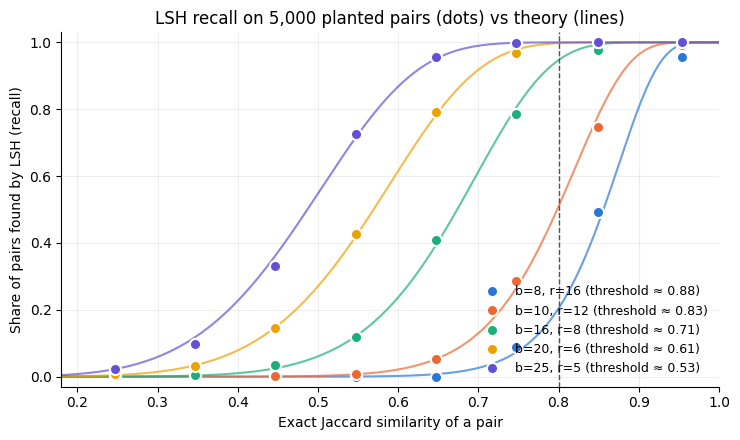

mean |measured - theoretical| recall over all settings and similarity levels: 0.006


,n_bands,n_rows_per_band,lsh_threshold_estimate,n_candidate_pairs,seconds_banding,n_real_pairs_found,n_real_pairs,real_recall_at_jaccard_threshold,real_recall_ci_low,real_recall_ci_high,real_share_of_candidates_at_or_above_threshold,largest_bucket_size,n_skipped_large_buckets,planted_recall_jaccard_0.8_to_0.9,planted_recall_jaccard_0.5_to_0.6
0,8,16,0.88,3404,0.4,154,165,0.933,0.885,0.962,0.995,49,0,0.493,0.000
1,10,12,0.83,3598,0.4,160,165,0.970,0.931,0.987,0.946,49,0,0.746,0.008
2,16,8,0.71,3931,0.7,165,165,1.000,0.977,1.000,0.869,49,0,0.979,0.118
3,20,6,0.61,7237,0.9,165,165,1.000,0.977,1.000,0.472,49,0,1.000,0.428
4,25,5,0.53,50512,1.7,165,165,1.000,0.977,1.000,0.068,90,0,1.000,0.725


In [30]:
similarity_grid = np.linspace(0, 1, 201)             # for the theory lines of the plot
random_generator = np.random.default_rng(RANDOM_SEED)
texts_before = reviews_before['review_text_normalised'].to_numpy()
long_review_rows = np.flatnonzero(reviews_before['word_count'].to_numpy() >= 50)
source_rows = random_generator.choice(long_review_rows, N_PLANTED_PAIRS, replace=False)
vocabulary = np.array(sorted({word for row in source_rows for word in texts_before[row].split()}))
shares_of_words_replaced = random_generator.uniform(0, MAX_SHARE_OF_WORDS_REPLACED, N_PLANTED_PAIRS)

edited_texts = [make_edited_copy(texts_before[row], share, vocabulary, random_generator)
                for row, share in zip(source_rows, shares_of_words_replaced)]
edited_shingle_ids = build_all_shingle_ids(edited_texts)
edited_signatures = compute_minhash_signatures(edited_shingle_ids)          # same hash functions as A4
original_signatures = signatures_before_near_duplicate_removal[source_rows]
planted_jaccard = np.array([compute_exact_jaccard(shingle_ids_before_near_duplicate_removal[row], edited_ids)
                            for row, edited_ids in zip(source_rows, edited_shingle_ids)])
planted_bin = np.asarray(pd.cut(planted_jaccard, PLANTED_JACCARD_BINS, labels=PLANTED_JACCARD_BIN_LABELS, right=False))
print(f'{N_PLANTED_PAIRS:,} planted pairs, exact Jaccard from {planted_jaccard.min():.2f} to {planted_jaccard.max():.2f}')

planted_rows = []
for n_bands, n_rows in LSH_SETTINGS:
    is_found = are_lsh_candidates(original_signatures, edited_signatures, n_bands, n_rows)
    for bin_label in PLANTED_JACCARD_BIN_LABELS:
        in_bin = planted_bin == bin_label
        if in_bin.any():
            planted_rows.append({
                'n_bands': n_bands, 'n_rows_per_band': n_rows, 'jaccard_bin': bin_label,
                'n_planted_pairs': int(in_bin.sum()),
                'mean_jaccard': float(planted_jaccard[in_bin].mean()),
                'measured_recall': float(is_found[in_bin].mean()),
                'theoretical_recall': float(lsh_candidate_probability(planted_jaccard[in_bin], n_bands, n_rows).mean()),
            })
    is_this_setting = (lsh_setting_comparison['n_bands'] == n_bands) & (lsh_setting_comparison['n_rows_per_band'] == n_rows)
    for low, high in [(0.8, 0.9), (0.5, 0.6)]:
        in_range = (planted_jaccard >= low) & (planted_jaccard < high)
        lsh_setting_comparison.loc[is_this_setting, f'planted_recall_jaccard_{low}_to_{high}'] = round(float(is_found[in_range].mean()), 3)
recall_by_jaccard_bin_planted = pd.DataFrame(planted_rows)
recall_by_jaccard_bin_planted['difference'] = (recall_by_jaccard_bin_planted['measured_recall']
                                               - recall_by_jaccard_bin_planted['theoretical_recall'])

# plot: theory (lines) vs measured on planted pairs (dots)
setting_colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6']   # fixed categorical order
figure, axis = plt.subplots(figsize=(7.5, 4.5))
for (n_bands, n_rows), color in zip(LSH_SETTINGS, setting_colors):
    axis.plot(similarity_grid, lsh_candidate_probability(similarity_grid, n_bands, n_rows),
              color=color, linewidth=1.5, alpha=0.7)
    measured = recall_by_jaccard_bin_planted[(recall_by_jaccard_bin_planted['n_bands'] == n_bands)
                                             & (recall_by_jaccard_bin_planted['n_rows_per_band'] == n_rows)]
    axis.plot(measured['mean_jaccard'], measured['measured_recall'], 'o', color=color, markersize=8,
              markeredgecolor='white', markeredgewidth=1.5,
              label=f'b={n_bands}, r={n_rows} (threshold ≈ {lsh_threshold(n_bands, n_rows):.2f})')
axis.axvline(JACCARD_THRESHOLD, color='#52514e', linewidth=1, linestyle='--')
axis.set_xlim(PLANTED_JACCARD_BINS[0] - 0.02, 1.0)
axis.set_ylim(-0.03, 1.03)
axis.set_xlabel('Exact Jaccard similarity of a pair')
axis.set_ylabel('Share of pairs found by LSH (recall)')
axis.set_title(f'LSH recall on {N_PLANTED_PAIRS:,} planted pairs (dots) vs theory (lines)')
axis.grid(alpha=0.2)
axis.spines[['top', 'right']].set_visible(False)
axis.legend(frameon=False, fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'lsh_recall_vs_theory.png', dpi=150)
plt.show()

# save for the report (the per-bin tables are in role_a_run_stats.json)
lsh_setting_comparison.to_csv(OUTPUT_DIR / 'lsh_setting_comparison.csv', index=False)
mean_absolute_difference = float(recall_by_jaccard_bin_planted['difference'].abs().mean())
run_stats['lsh_threshold_analysis'] = {
    'ground_truth': ground_truth_stats,
    # to_json -> json.loads turns numpy numbers into plain Python numbers for the JSON file
    'settings': json.loads(lsh_setting_comparison.to_json(orient='records')),
    'recall_by_jaccard_bin_real': json.loads(recall_by_jaccard_bin_real.round(4).to_json(orient='records')),
    'planted_experiment': {
        'n_planted_pairs': N_PLANTED_PAIRS,
        'max_share_of_words_replaced': MAX_SHARE_OF_WORDS_REPLACED,
        'mean_absolute_difference_measured_vs_theory': round(mean_absolute_difference, 4),
        'recall_by_jaccard_bin': json.loads(recall_by_jaccard_bin_planted.round(4).to_json(orient='records')),
    },
}
print(f'mean |measured - theoretical| recall over all settings and similarity levels: {mean_absolute_difference:.3f}')
lsh_setting_comparison

### Conclusion of A5
**How to read it**: *real recall* = share of real pairs with Jaccard ≥ 0.8 that became candidates (missed pairs are never verified, so never removed), with its 95% confidence interval; *candidates* = cost of the verification step; *planted recall at 0.8-0.9* = how well a setting catches pairs just above the threshold.

**What the evidence is worth.** Only about 165 real pairs have Jaccard ≥ 0.8, and only about 19 lie between 0.8 and 0.9, so the confidence intervals of the real recall are wide. The **planted pairs** (hundreds per similarity level) are the stronger evidence that the implementation behaves as the theory says; the real pairs confirm it on real copies.

**Why 16 × 8**: the cheapest setting that finds every real pair with Jaccard ≥ 0.8. Fewer bands miss real pairs; more bands only add candidates that the verification then rejects. Brute force grows with the square of the number of reviews, LSH roughly linearly, so the gap widens with more data.

The numbers below are **printed from this run**, so they always match the outputs above (earlier versions had them typed by hand, and they went out of date).

In [31]:
analysis = run_stats['lsh_threshold_analysis']
ground_truth = analysis['ground_truth']
planted = analysis['planted_experiment']
settings_table = lsh_setting_comparison.set_index(['n_bands', 'n_rows_per_band'])
chosen_setting_key = (N_BANDS, N_ROWS_PER_BAND)

best_real_recall = settings_table['real_recall_at_jaccard_threshold'].max()
cheapest_best_setting = settings_table.loc[settings_table['real_recall_at_jaccard_threshold'] == best_real_recall,
                                           'n_candidate_pairs'].idxmin()
seconds = run_stats['near_duplicates']['seconds']
seconds_lsh_pipeline = seconds['minhash'] + seconds['lsh_banding'] + seconds['verification']
minutes_brute_force_all_pairs = ground_truth['estimated_hours_brute_force_all_pairs'] * 60
n_all_pairs_searched = run_stats['near_duplicates']['n_all_possible_pairs']

print('1. Implementation vs theory')
print(f"   On {planted['n_planted_pairs']:,} planted pairs, measured recall differs from 1 - (1 - s^r)^b by "
      f"{planted['mean_absolute_difference_measured_vs_theory']:.3f} on average "
      f"({len(LSH_SETTINGS)} settings x {len(PLANTED_JACCARD_BIN_LABELS)} similarity levels).")
print('2. Real ground truth')
print(f"   {ground_truth['n_pairs_compared']:,} within-condition pairs ({ground_truth['share_of_all_pairs_compared']:.1%} of all "
      f"pairs) compared by brute force: {ground_truth['n_pairs_at_or_above_min_jaccard']} pairs with Jaccard >= "
      f"{GROUND_TRUTH_MIN_JACCARD}, {ground_truth['n_pairs_at_or_above_threshold']} with Jaccard >= {JACCARD_THRESHOLD}.")
print('3. Settings on the real data (real recall at Jaccard >= threshold, with its 95% confidence interval)')
for (n_bands, n_rows), setting in settings_table.iterrows():
    marker = '   <- chosen' if (n_bands, n_rows) == chosen_setting_key else ''
    print(f"   {n_bands:2d} x {n_rows:2d}: {int(setting['n_candidate_pairs']):>8,} candidates | real recall "
          f"{setting['real_recall_at_jaccard_threshold']:.3f} [{setting['real_recall_ci_low']:.3f}, "
          f"{setting['real_recall_ci_high']:.3f}] | planted recall at 0.8-0.9: "
          f"{setting['planted_recall_jaccard_0.8_to_0.9']:.3f}{marker}")
print('4. Choice')
if chosen_setting_key == cheapest_best_setting:
    chosen_candidates = settings_table.loc[chosen_setting_key, 'n_candidate_pairs']
    more_candidates = settings_table.loc[settings_table['n_candidate_pairs'] > chosen_candidates, 'n_candidate_pairs']
    print(f'   {N_BANDS} x {N_ROWS_PER_BAND} is the cheapest setting with the highest real recall ({best_real_recall:.3f}).')
    if len(more_candidates):
        print(f'   The looser settings produce {more_candidates.min() / chosen_candidates:.1f} to '
              f'{more_candidates.max() / chosen_candidates:.1f} times as many candidates without finding more real pairs.')
else:
    print(f'   WARNING: the cheapest setting with the highest real recall is {cheapest_best_setting[0]} x '
          f'{cheapest_best_setting[1]}, not the chosen {N_BANDS} x {N_ROWS_PER_BAND}: revisit N_BANDS / N_ROWS_PER_BAND.')
print('5. Brute force vs LSH')
print(f"   Brute force: {ground_truth['seconds_brute_force']:.0f} s for {ground_truth['n_pairs_compared'] / 1e6:.0f} million "
      f"pairs, so about {minutes_brute_force_all_pairs:.0f} minutes for all {n_all_pairs_searched / 1e9:.1f} billion pairs.")
print(f"   MinHash + LSH + verification: {seconds_lsh_pipeline / 60:.1f} minutes (MinHash {seconds['minhash']:.0f} s, "
      f"banding {seconds['lsh_banding']:.1f} s, verification {seconds['verification']:.1f} s), "
      f"about {minutes_brute_force_all_pairs * 60 / seconds_lsh_pipeline:.0f} times faster.")

analysis['conclusion'] = {
    'chosen_setting': list(chosen_setting_key),
    'cheapest_setting_with_best_real_recall': [int(value) for value in cheapest_best_setting],
    'best_real_recall': float(best_real_recall),
    'seconds_minhash_lsh_verification': round(seconds_lsh_pipeline, 1),
    'estimated_minutes_brute_force_all_pairs': round(minutes_brute_force_all_pairs, 1),
}

1. Implementation vs theory
   On 5,000 planted pairs, measured recall differs from 1 - (1 - s^r)^b by 0.006 on average (5 settings x 8 similarity levels).
2. Real ground truth
   304,915,565 within-condition pairs (3.7% of all pairs) compared by brute force: 276 pairs with Jaccard >= 0.5, 165 with Jaccard >= 0.8.
3. Settings on the real data (real recall at Jaccard >= threshold, with its 95% confidence interval)
    8 x 16:    3,404 candidates | real recall 0.933 [0.885, 0.962] | planted recall at 0.8-0.9: 0.493
   10 x 12:    3,598 candidates | real recall 0.970 [0.931, 0.987] | planted recall at 0.8-0.9: 0.746
   16 x  8:    3,931 candidates | real recall 1.000 [0.977, 1.000] | planted recall at 0.8-0.9: 0.979   <- chosen
   20 x  6:    7,237 candidates | real recall 1.000 [0.977, 1.000] | planted recall at 0.8-0.9: 1.000
   25 x  5:   50,512 candidates | real recall 1.000 [0.977, 1.000] | planted recall at 0.8-0.9: 1.000
4. Choice
   16 x 8 is the cheapest setting with the highest 

## A6 · Similar-story search across drugs (word version)
**Goal:** find patients who tell **the same story about different medicines**, for example *"gained weight, mood swings, stopped after two months"* about two different pills. If many patients of drug X tell the same stories as patients of drug Y, patients experience X and Y in a similar way (research question 3), and D can check whether X and Y also share a pharmacological class.

**Why LSH is needed here:** more than 100,000 long reviews give several billion pairs to compare. LSH reduces that to at most a few million candidates that are cheap to check (as A5 showed for copies).

**Word version vs meaning version.** Here two reviews are similar when they share many **meaningful words**. Later, with C's Sentence-BERT embeddings, a *meaning version* will also match different words with the same sense ("can't sleep" ≈ "insomnia"), and the two will be compared.

Steps:
1. **Drug families**: brand and generic names of the same medicine count as one drug.
2. **Meaningful words**: each review becomes a set of words that say something about the experience.
3. **MinHash signatures** of those word sets (same code as A4).
4. **Choose the LSH setting** that is as loose as the computer can afford to verify.
5. **Find and verify** similar pairs; pairs from **different** drug families are the results.
6. **Look at the stories** to check that they really are similar, and look inside the bucket LSH had to skip.
7. **Drug-to-drug table** for D: which drugs share the most stories, and a **permutation test** that says which of them share more than chance.

### 1 · Drug families: one medicine, one identity
After A3, a review keeps one drug name, which can be the brand (*Nexplanon*) or the generic (*Etonogestrel*). If we did nothing, a Nexplanon review and an Etonogestrel review would count as two *different* drugs telling the same story, when it is the same medicine.

**How:** names that appeared on the same review (the `drug_name_aliases` list from A3) are linked, and every group of linked names becomes one **drug family** (connected components of a graph, the same idea as in A4). The family takes the name with the most reviews. The table of families is saved as `drug_families.csv`; it can also help D choose one name per drug.

Check the printed families with the most names: a family should be one active ingredient (several brands of the same pill), not unrelated medicines.

In [32]:
def build_drug_families(drug_name_alias_lists):
    # names that appeared on the same review are one medicine: link them and take connected groups
    all_drug_names = sorted({name for aliases in drug_name_alias_lists for name in aliases})
    name_index = {name: index for index, name in enumerate(all_drug_names)}
    links = np.array([(name_index[aliases[0]], name_index[other_name])
                      for aliases in drug_name_alias_lists for other_name in aliases[1:]], dtype=np.int64).reshape(-1, 2)
    name_graph = coo_matrix((np.ones(len(links)), (links[:, 0], links[:, 1])),
                            shape=(len(all_drug_names), len(all_drug_names)))
    _, family_of_name = connected_components(name_graph, directed=False)
    return dict(zip(all_drug_names, family_of_name.tolist()))


family_id_of_drug_name = build_drug_families(deduplicated_reviews['drug_name_aliases'])
review_drug_family_id = deduplicated_reviews['drug_name'].map(family_id_of_drug_name).to_numpy()

reviews_per_drug_name = deduplicated_reviews['drug_name'].value_counts()
drug_families = (pd.DataFrame({'drug_name': list(family_id_of_drug_name),
                               'drug_family_id': list(family_id_of_drug_name.values())})
                 .assign(n_reviews=lambda table: table['drug_name'].map(reviews_per_drug_name).fillna(0).astype(int))
                 .sort_values(['n_reviews', 'drug_name'], ascending=[False, True])
                 .groupby('drug_family_id', sort=False)
                 .agg(drug_family_name=('drug_name', 'first'),
                      drug_names=('drug_name', ' | '.join),
                      n_drug_names=('drug_name', 'size'),
                      n_reviews=('n_reviews', 'sum'))
                 .sort_values('n_reviews', ascending=False))
drug_family_name_of_id = drug_families['drug_family_name']
drug_families.to_csv(OUTPUT_DIR / 'drug_families.csv')

print(f'{len(family_id_of_drug_name):,} drug names grouped into {len(drug_families):,} drug families')
print('\nfamilies with the most names (check that each is one medicine):')
drug_families.sort_values('n_drug_names', ascending=False).head(8)

3,669 drug names grouped into 1,388 drug families

families with the most names (check that each is one medicine):


,drug_family_name,drug_names,n_drug_names,n_reviews
drug_family_id,,,,
169,Ethinyl estradiol / norethindrone,Ethinyl estradiol / norethindrone | Lo Loestrin Fe | Microgestin Fe 1 / 20 | Minastrin 24 Fe | Junel Fe 1 / 20 | femhrt | Balziva | Junel Fe 24 | ...,54,3752
129,Ethinyl estradiol / levonorgestrel,Ethinyl estradiol / levonorgestrel | Seasonique | Orsythia | Lutera | Sronyx | LoSeasonique | Levora | Camrese | Alesse | Portia | Chateal | Lybre...,32,2500
548,Estradiol,Estradiol | Vagifem | Climara | Femring | Estradiol Patch | Evamist | Estrace | Minivelle | Elestrin | Divigel | Estraderm | Vivelle | Estrasorb |...,18,310
797,Ethinyl estradiol / norgestimate,Ethinyl estradiol / norgestimate | Sprintec | Mononessa | Previfem | Tri-Estarylla | Tri-Lo-Estarylla | Estarylla | Mono-Linyah | Ortho Cyclen | O...,18,2787
225,Desogestrel / ethinyl estradiol,Desogestrel / ethinyl estradiol | Reclipsen | Ortho-Cept | Mircette | Cyred | Enskyce | Pimtrea | Juleber | Emoquette | Apri | Azurette | Caziant ...,17,686
536,"Multivitamin, prenatal","Multivitamin, prenatal | CitraNatal 90 DHA | Vitafol-OB+DHA | CitraNatal Assure | Concept DHA | Duet DHA | Natelle One | Neevo DHA | OB Complete G...",16,57
544,Ocular lubricant,Ocular lubricant | Systane | Lacrisert | Systane Ultra | GenTeal | Hypotears | Systane Balance | Tears Again | TheraTears | Refresh Liquigel | Ref...,14,52
107,Levonorgestrel,Levonorgestrel | Skyla | Plan B | Plan B One-Step | Mirena | Liletta | Next Choice | My Way | Take Action | Opcicon One-Step | Aftera | EContra EZ...,14,4921


### 2 · Turn each review into a set of meaningful words
A story is told by words like *weight*, *gain*, *mood*, *insomnia*, *stopped*, not by *the*, *and*, *I*. Each review (with at least `MIN_WORDS_FOR_STORY` words) becomes the **set** of its meaningful words:

| Rule | Example | Why |
|---|---|---|
| Drop common English words (*stop words*) | *the, and, my, was* | They appear in every review and say nothing about the experience |
| Drop drug names | *sertraline, zoloft* | We want reviews that share an **experience**, not reviews that mention the same medicine |
| Drop words containing digits, and words of 1-2 letters | *10, 1st, 50mg, ok* | Doses and dates differ without changing the story |
| Drop month and weekday names | *january, june, monday* | Patients date their story; sharing a date is not sharing an experience |
| Reduce words to their root (*stemming*) | *gained, gaining* → *gain* | The same idea written in different forms should match |
| Mark negations | *no weight gain* → *no_weight, gain* | "No weight gain" and "weight gain" are opposite stories |
| Drop words in more than `MAX_DOCUMENT_SHARE` of reviews | *side, effect, take* | Almost every review has them, so sharing them means nothing |
| Drop words in fewer than `MIN_DOCUMENT_COUNT` reviews | typos | Two reviews can almost never share them |

Reviews left with fewer than `MIN_CONTENT_WORDS` meaningful words are skipped. The printed example shows one review before and after.

In [33]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
try:
    from nltk.stem import PorterStemmer
    stem_word = PorterStemmer().stem
except ImportError:                                    # without nltk the words are used as they are
    print('nltk not available: words are not reduced to their root')
    stem_word = lambda word: word

NEGATION_WORDS = {'no', 'not', 'never', 'nor', 'without', 'didnt', 'dont', 'doesnt', 'wasnt', 'isnt',
                  'cant', 'couldnt', 'wont', 'wouldnt', 'havent', 'hasnt', 'hadnt', 'arent', 'werent'}
CALENDAR_WORDS = {'january', 'february', 'march', 'april', 'may', 'june', 'july', 'august', 'september',
                  'october', 'november', 'december', 'jan', 'feb', 'apr', 'jun', 'jul', 'aug', 'sep', 'sept',
                  'oct', 'nov', 'dec', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday'}


def find_drug_name_words(drug_names):
    # one-word drug names and one-word parts of combinations ('Ethinyl estradiol / norgestimate' -> 'norgestimate')
    drug_name_words = set()
    for drug_name in drug_names:
        for part in drug_name.split('/'):
            part_words = normalise_review_text(part).split()
            if len(part_words) == 1:
                drug_name_words.add(part_words[0])
    return drug_name_words


def text_to_story_words(text, root_of_word):
    # set of meaningful word roots; a negation turns the next meaningful word into 'no_<root>'
    story_words, negate_next_word = set(), False
    for word in text.split():
        if word in NEGATION_WORDS:
            negate_next_word = True
            continue
        root = root_of_word.get(word)
        if root is None:                               # stop word, drug name, number, date or very short word
            continue
        story_words.add('no_' + root if negate_next_word else root)
        negate_next_word = False
    return story_words


story_rows = np.flatnonzero(deduplicated_reviews['word_count'].to_numpy() >= MIN_WORDS_FOR_STORY)
story_texts = deduplicated_reviews['review_text_normalised'].to_numpy()[story_rows]

drug_name_words = find_drug_name_words(family_id_of_drug_name)
vocabulary = {word for text in story_texts for word in text.split()}
root_of_word = {word: stem_word(word) for word in vocabulary
                if len(word) > 2 and not any(character.isdigit() for character in word) and word not in CALENDAR_WORDS
                and word not in ENGLISH_STOP_WORDS and word not in NEGATION_WORDS and word not in drug_name_words}
story_word_sets = [text_to_story_words(text, root_of_word) for text in story_texts]

# keep only words that are neither almost everywhere nor almost nowhere
document_count = Counter(word for word_set in story_word_sets for word in word_set)
max_document_count = MAX_DOCUMENT_SHARE * len(story_word_sets)
too_common_words = sorted((word for word, count in document_count.items() if count > max_document_count),
                          key=lambda word: -document_count[word])
kept_words = {word for word, count in document_count.items() if MIN_DOCUMENT_COUNT <= count <= max_document_count}
story_word_sets = [word_set & kept_words for word_set in story_word_sets]

has_enough_words = np.array([len(word_set) >= MIN_CONTENT_WORDS for word_set in story_word_sets])
story_rows = story_rows[has_enough_words]
story_word_sets = [word_set for word_set, keep in zip(story_word_sets, has_enough_words) if keep]
story_review_family_id = review_drug_family_id[story_rows]

print(f'{len(story_rows):,} reviews with at least {MIN_WORDS_FOR_STORY} words and {MIN_CONTENT_WORDS} meaningful words')
print(f'mean meaningful words per review: {np.mean([len(word_set) for word_set in story_word_sets]):.1f}')
print(f'{len(drug_name_words):,} drug-name words and {len(too_common_words)} very common words dropped:',
      too_common_words[:20])
example_row = story_rows[0]
print('\nexample review:', deduplicated_reviews['review_text_clean'].iloc[example_row][:300])
print('its meaningful words:', sorted(story_word_sets[0]))

115,463 reviews with at least 20 words and 8 meaningful words
mean meaningful words per review: 28.2
2,513 drug-name words and 9 very common words dropped: ['day', 'year', 'month', 'work', 'start', 'take', 'effect', 'week', 'time']

example review: Been on the depo injection since January 2015, had bleeding but it stopped after a while. When I had another injection in June, I didn't bleed for about a month. Started spotting mid-July and since approx. August 1st, I have been bleeding constantly, heavy enough to use pads and now it's almost Nove
its meaningful words: ['approx', 'await', 'bleed', 'chang', 'constantli', 'contracept', 'current', 'depo', 'doctor', 'fork', 'happen', 'heavi', 'inject', 'like', 'mid', 'money', 'no_bleed', 'no_let', 'no_long', 'pad', 'sanitari', 'shouldnt', 'sick', 'spot', 'stop', 'ultrasound', 'use']


### 3 · MinHash signatures of the word sets
Exactly as in A4, but the pieces are now **words** instead of 5-letter shingles: each word gets a number (CRC32) and each review gets a signature of 128 MinHash values. The same hash functions are reused, so the property still holds: two reviews agree in a signature position with probability equal to the Jaccard similarity of their word sets.

In [34]:
started = time.perf_counter()
story_word_ids = [np.sort(np.fromiter((zlib.crc32(word.encode('utf-8')) for word in word_set),
                                      dtype=np.uint64, count=len(word_set)))
                  for word_set in story_word_sets]
story_signatures = compute_minhash_signatures(story_word_ids)
print(story_signatures.shape, f'{time.perf_counter() - started:.0f} s')

(115463, 128) 9 s


### 4 · Choose the LSH setting
Two different patients telling a similar story share far fewer words than a copy does, so we look for word-set Jaccard ≥ `STORY_JACCARD_THRESHOLD` (0.3), much lower than the 0.8 used for copies. A lower threshold needs a **looser** LSH setting (fewer rows per band), which finds more pairs but also produces more candidates to verify.

**How we choose:** for each setting in `STORY_LSH_SETTINGS`, from loose to strict, we first **count** how many candidates it would produce (cheap: only bucket sizes are counted, no pairs are built). We use the **loosest setting whose count stays below `MAX_STORY_CANDIDATES`**, so we find as many similar stories as the computer can afford to verify. The table also shows each setting's theoretical recall at the threshold, so the price of a stricter setting is visible.

*Budget:* with a budget of 3 million the choice would be 32 × 4, which in theory finds only 23% of the pairs at Jaccard 0.3. 42 × 3 finds 68% for about 20 million candidates, which fit comfortably in Kaggle's memory, so the budget is 25 million.

In [35]:
def count_lsh_candidates(signatures, n_bands, n_rows_per_band, max_bucket_size=1000):
    # pairs inside each bucket, summed over bands, WITHOUT building them (cheap). A pair found in two bands is
    # counted twice, so this is an upper bound. Large buckets are counted too: skipping them would hide lost pairs.
    n_candidate_pairs, n_large_buckets = 0, 0
    for band_index in range(n_bands):
        bucket_keys = compute_band_keys(signatures, band_index, n_rows_per_band)
        _, bucket_sizes = np.unique(bucket_keys, return_counts=True)
        bucket_sizes = bucket_sizes[bucket_sizes > 1].astype(np.int64)
        n_large_buckets += int((bucket_sizes > max_bucket_size).sum())
        n_candidate_pairs += int((bucket_sizes * (bucket_sizes - 1) // 2).sum())
    return n_candidate_pairs, n_large_buckets


story_setting_rows = []
for n_bands, n_rows in STORY_LSH_SETTINGS:
    n_candidates, n_skipped = count_lsh_candidates(story_signatures, n_bands, n_rows)
    story_setting_rows.append({
        'n_bands': n_bands, 'n_rows_per_band': n_rows,
        'lsh_threshold_estimate': round(lsh_threshold(n_bands, n_rows), 2),
        'theoretical_recall_at_story_threshold': round(float(lsh_candidate_probability(STORY_JACCARD_THRESHOLD, n_bands, n_rows)), 3),
        'counted_candidate_pairs': n_candidates,
        'n_buckets_over_1000_reviews': n_skipped,
    })
story_setting_comparison = pd.DataFrame(story_setting_rows)
affordable = story_setting_comparison[story_setting_comparison['counted_candidate_pairs'] <= MAX_STORY_CANDIDATES]
chosen_setting = affordable.iloc[0] if len(affordable) else story_setting_comparison.iloc[-1]
story_n_bands, story_n_rows = int(chosen_setting['n_bands']), int(chosen_setting['n_rows_per_band'])
print(f'chosen setting: {story_n_bands} bands x {story_n_rows} rows '
      f'(theoretical recall at Jaccard {STORY_JACCARD_THRESHOLD}: {chosen_setting["theoretical_recall_at_story_threshold"]:.2f})')
story_setting_comparison

chosen setting: 42 bands x 3 rows (theoretical recall at Jaccard 0.3: 0.68)


,n_bands,n_rows_per_band,lsh_threshold_estimate,theoretical_recall_at_story_threshold,counted_candidate_pairs,n_buckets_over_1000_reviews
0,64,2,0.12,0.998,568111091,127
1,42,3,0.29,0.683,20864643,1
2,32,4,0.42,0.229,995137,0
3,25,5,0.53,0.059,84996,0
4,21,6,0.60,0.015,6760,0
5,16,8,0.71,0.001,158,0


### 5 · Find and verify similar stories
1. **LSH** with the chosen setting gives candidate pairs.
2. **Quick filter**: the MinHash estimate (share of equal signature values) must be at least `STORY_JACCARD_THRESHOLD − 0.1`. With 128 values the estimate is usually within 0.04 of the true value, so a margin of 0.1 keeps almost every real pair while discarding most of the rest cheaply.
3. **Exact check**: the true Jaccard of the two word sets must be at least `STORY_JACCARD_THRESHOLD`.
4. **Different medicines only**: pairs from **different** drug families are the results (`similar_story_pairs`). Pairs from the **same** family are verified too but kept apart in `all_similar_story_pairs`: they never reach the results or D's table, and only the null model of step 7 uses them (after shuffling drug labels, two reviews of one drug can carry two different labels). They add about 5% of the candidates.

In [36]:
started = time.perf_counter()
story_candidates, story_lsh_info = find_lsh_candidate_pairs(story_signatures, story_n_bands, story_n_rows)
seconds_story_lsh = time.perf_counter() - started

is_cross_drug = story_review_family_id[story_candidates[:, 0]] != story_review_family_id[story_candidates[:, 1]]

# quick filter with the MinHash estimate, in chunks to limit memory (all candidates, also same-family pairs)
chunk_size = 200_000
estimated_jaccard = np.concatenate([
    estimate_jaccard_from_signatures(story_signatures, story_candidates[start:start + chunk_size])
    for start in range(0, len(story_candidates), chunk_size)]) if len(story_candidates) else np.empty(0)
is_promising = estimated_jaccard >= STORY_JACCARD_THRESHOLD - 0.1
promising_pairs = story_candidates[is_promising]

# exact Jaccard of the word sets
promising_jaccard = np.array([len(story_word_sets[i] & story_word_sets[j]) / len(story_word_sets[i] | story_word_sets[j])
                              for i, j in promising_pairs], dtype=float)
is_similar_story = promising_jaccard >= STORY_JACCARD_THRESHOLD
similar_pairs, similar_jaccard = promising_pairs[is_similar_story], promising_jaccard[is_similar_story]
seconds_story_total = time.perf_counter() - started

rows_a, rows_b = story_rows[similar_pairs[:, 0]], story_rows[similar_pairs[:, 1]]
first, second = deduplicated_reviews.iloc[rows_a], deduplicated_reviews.iloc[rows_b]
all_similar_story_pairs = pd.DataFrame({
    'story_index_a': similar_pairs[:, 0], 'story_index_b': similar_pairs[:, 1],
    'review_id_a': first['review_id'].to_numpy(), 'review_id_b': second['review_id'].to_numpy(),
    'drug_family_id_a': story_review_family_id[similar_pairs[:, 0]],
    'drug_family_id_b': story_review_family_id[similar_pairs[:, 1]],
    'drug_name_a': first['drug_name'].to_numpy(), 'drug_name_b': second['drug_name'].to_numpy(),
    'condition_name_a': first['condition_name'].to_numpy(), 'condition_name_b': second['condition_name'].to_numpy(),
    'rating_a': first['rating'].to_numpy(), 'rating_b': second['rating'].to_numpy(),
    'word_jaccard': similar_jaccard,
    'shared_words': [' '.join(sorted(story_word_sets[i] & story_word_sets[j])) for i, j in similar_pairs],
}).sort_values('word_jaccard', ascending=False, ignore_index=True)
all_similar_story_pairs['same_condition'] = all_similar_story_pairs['condition_name_a'] == all_similar_story_pairs['condition_name_b']
# same patient: same WORDING, measured with the 5-letter shingles of A4 (word sets only measure the topic)
all_similar_story_pairs['character_jaccard'] = [
    compute_exact_jaccard(shingle_id_arrays[story_rows[i]], shingle_id_arrays[story_rows[j]])
    for i, j in zip(all_similar_story_pairs['story_index_a'], all_similar_story_pairs['story_index_b'])]
all_similar_story_pairs['likely_same_patient'] = all_similar_story_pairs['character_jaccard'] >= SAME_PATIENT_CHARACTER_JACCARD
all_similar_story_pairs['similar_rating'] = (all_similar_story_pairs['rating_a'] - all_similar_story_pairs['rating_b']).abs() <= MAX_RATING_DIFFERENCE
all_similar_story_pairs['counts_as_shared_story'] = ~all_similar_story_pairs['likely_same_patient'] & all_similar_story_pairs['similar_rating']

# the results: pairs from DIFFERENT drug families (same columns and order as before)
is_same_family_pair = all_similar_story_pairs['drug_family_id_a'] == all_similar_story_pairs['drug_family_id_b']
similar_story_pairs = all_similar_story_pairs[~is_same_family_pair].reset_index(drop=True)

n_story_pairs_possible = len(story_rows) * (len(story_rows) - 1) // 2
run_stats['similar_stories'] = {
    'version': 'word sets (stop words, drug names and very common or rare words removed; stemming; negations marked)',
    'n_reviews_searched': int(len(story_rows)),
    'mean_meaningful_words_per_review': round(float(np.mean([len(word_set) for word_set in story_word_sets])), 1),
    'n_drug_families': int(len(drug_families)),
    'story_jaccard_threshold': STORY_JACCARD_THRESHOLD,
    'chosen_n_bands': story_n_bands, 'chosen_n_rows_per_band': story_n_rows,
    'n_all_possible_pairs': n_story_pairs_possible,
    'n_lsh_candidate_pairs': int(len(story_candidates)),
    'n_cross_drug_candidates': int(is_cross_drug.sum()),
    'n_after_minhash_filter': int((is_promising & is_cross_drug).sum()),
    'n_similar_story_pairs': int(len(similar_story_pairs)),
    'same_patient_character_jaccard': SAME_PATIENT_CHARACTER_JACCARD,
    'n_likely_same_patient': int(similar_story_pairs['likely_same_patient'].sum()),
    'max_rating_difference': MAX_RATING_DIFFERENCE,
    'n_left_out_for_rating_difference': int((~similar_story_pairs['likely_same_patient'] & ~similar_story_pairs['similar_rating']).sum()),
    'n_shared_stories': int(similar_story_pairs['counts_as_shared_story'].sum()),
    'share_same_condition': round(float(similar_story_pairs['same_condition'].mean()), 3) if len(similar_story_pairs) else None,
    'n_same_family_candidates_verified_for_null_model': int((~is_cross_drug).sum()),
    'n_same_family_similar_pairs': int(is_same_family_pair.sum()),
    **story_lsh_info,
    'seconds_lsh': round(seconds_story_lsh, 1), 'seconds_total': round(seconds_story_total, 1),
    'setting_comparison': json.loads(story_setting_comparison.to_json(orient='records')),
}
print(json.dumps({key: value for key, value in run_stats['similar_stories'].items() if key != 'setting_comparison'}, indent=1))
print('\nword Jaccard of the similar stories found:')
print(pd.cut(similar_story_pairs['word_jaccard'], [STORY_JACCARD_THRESHOLD, 0.4, 0.5, 0.6, 0.8, 1.0001], right=False)
        .value_counts().sort_index().to_string())
print('\ncharacter Jaccard (same wording) of the same pairs:')
print(pd.cut(similar_story_pairs['character_jaccard'], [0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0001], right=False)
        .value_counts().sort_index().to_string())

{
 "version": "word sets (stop words, drug names and very common or rare words removed; stemming; negations marked)",
 "n_reviews_searched": 115463,
 "mean_meaningful_words_per_review": 28.2,
 "n_drug_families": 1388,
 "story_jaccard_threshold": 0.3,
 "chosen_n_bands": 42,
 "chosen_n_rows_per_band": 3,
 "n_all_possible_pairs": 6665794453,
 "n_lsh_candidate_pairs": 18730368,
 "n_cross_drug_candidates": 17897128,
 "n_after_minhash_filter": 279858,
 "n_similar_story_pairs": 2254,
 "same_patient_character_jaccard": 0.3,
 "n_likely_same_patient": 31,
 "max_rating_difference": 3,
 "n_left_out_for_rating_difference": 512,
 "n_shared_stories": 1711,
 "share_same_condition": 0.444,
 "n_same_family_candidates_verified_for_null_model": 833240,
 "n_same_family_similar_pairs": 936,
 "n_skipped_large_buckets": 1,
 "largest_bucket_size": 1928,
 "seconds_lsh": 56.0,
 "seconds_total": 70.2
}

word Jaccard of the similar stories found:
word_jaccard
[0.3, 0.4)    2128
[0.4, 0.5)      97
[0.5, 0.6)       

### 6 · Look at the stories
Numbers alone do not prove that two reviews tell a similar story. As the project plan says, we **check a sample by hand**. Reading the pairs showed two kinds of pairs that are **not** two patients sharing an experience:

| Problem | Example | Rule |
|---|---|---|
| **Same patient** posting nearly the same review for two medicines | Sertraline and Paxil, Levofloxacin and Cipro (word Jaccard only 0.5-0.6) | Word sets measure the *topic*; the 5-letter shingles of A4 measure the *wording*. Different people rarely write the same sentences, so a character Jaccard ≥ `SAME_PATIENT_CHARACTER_JACCARD` (0.3) flags `likely_same_patient`. 2,168 pairs have character Jaccard below 0.2, 55 between 0.2 and 0.3, only 4 between 0.3 and 0.4 and 27 above: 0.3 sits in that natural gap (a 0.4 cut missed Lexapro and Citalopram at 0.39, the same author) |
| **Opposite experiences** with the same words | "gained weight" (rating 1) vs "no problems with weight gain" (rating 8): the negation marks only the next word | The rating sums up how the experience went, so a shared story also needs ratings at most `MAX_RATING_DIFFERENCE` (3) apart |

Pairs that pass both rules are flagged `counts_as_shared_story`; all pairs stay in `similar_story_pairs.parquet` with their flags. If the pairs just above the threshold still do not look alike, raise `STORY_JACCARD_THRESHOLD`.

In [37]:
def show_story_pairs(pair_table, n_pairs=5):
    for _, pair in pair_table.head(n_pairs).iterrows():
        print(f"word Jaccard {pair['word_jaccard']:.2f} | character Jaccard {pair['character_jaccard']:.2f} | shared words: {pair['shared_words']}")
        for label in ['a', 'b']:
            review = deduplicated_reviews.iloc[int(story_rows[int(pair[f'story_index_{label}'])])]
            print(f"  {label.upper()}: {review['drug_name']} | {review['condition_name']} | rating {review['rating']}")
            print(f"     {review['review_text_clean'][:300]}")
        print()


is_same_patient = similar_story_pairs['likely_same_patient']
is_shared_story = similar_story_pairs['counts_as_shared_story']
is_opposite = ~is_same_patient & ~similar_story_pairs['similar_rating']
print(f'=== likely the same patient reviewing two medicines ({int(is_same_patient.sum())} pairs, left out) ===')
show_story_pairs(similar_story_pairs[is_same_patient].sort_values('character_jaccard'), 3)   # the least obvious ones
print(f'=== different patients, ratings more than {MAX_RATING_DIFFERENCE} apart ({int(is_opposite.sum())} pairs, left out) ===')
show_story_pairs(similar_story_pairs[is_opposite], 3)
print(f'=== shared stories: most similar ({int(is_shared_story.sum())} pairs kept) ===')
show_story_pairs(similar_story_pairs[is_shared_story], 5)
print('=== shared stories just above the threshold ===')
just_above_story_threshold = is_shared_story & (similar_story_pairs['word_jaccard'] < STORY_JACCARD_THRESHOLD + 0.03)
show_story_pairs(similar_story_pairs[just_above_story_threshold].sample(min(5, int(just_above_story_threshold.sum())),
                                                                        random_state=RANDOM_SEED), 5)

=== likely the same patient reviewing two medicines (31 pairs, left out) ===
word Jaccard 0.39 | character Jaccard 0.31 | shared words: appetit constip disc get gradual help herniat inject loss lower morn pain realli return seri slight tablet
  A: Tramadol | Pain | rating 7
     I have a herniated disc in my lower back. The pain was intense. I had a series of injections that really helped, but some of the pain gradually returned but not as intense as the orginal pain was. I usually take one 50mg tablet of tramadol and a tablet of diclofenac every morning and it gets me thro
  B: Diclofenac | Back Pain | rating 9
     I'm a 61 year old male. I have a herniated disc in my lower back. I was in severe pain. I received a series of steroid injections that really helped. Gradually the pain returned but not near as severe as the initial pain but bad enough to cause me a lot of discomfort. I've since been taking one dicl

word Jaccard 0.44 | character Jaccard 0.37 | shared words: afford have he

### Inside the bucket LSH had to skip
`find_lsh_candidate_pairs` skips any bucket with more than 1,000 reviews, because a bucket of *m* reviews gives *m*(*m* − 1)/2 pairs (2,000 reviews → 2 million pairs), almost all of them unrelated. With the loose setting of A6 (only 3 rows per band), a few very common words can be enough to put many reviews in one bucket.

Skipping is a trade-off, so here we **measure what it cost**. For each skipped bucket:
- which words almost all its reviews share (they explain why the bucket is so big);
- on `N_SAMPLED_PAIRS_PER_SKIPPED_BUCKET` random pairs from the bucket: the share that are similar stories (word Jaccard ≥ threshold), and how many of those were **found anyway** through another band;
- from that, an estimate of the similar pairs **lost** by skipping, for the report's limitations.

In [38]:
def find_large_lsh_buckets(signatures, n_bands, n_rows_per_band, max_bucket_size=1000):
    # (band, member rows) of every bucket with more than max_bucket_size reviews: the ones find_lsh_candidate_pairs skips
    large_buckets = []
    for band_index in range(n_bands):
        bucket_keys = compute_band_keys(signatures, band_index, n_rows_per_band)   # same keys as find_lsh_candidate_pairs
        _, bucket_of_review, bucket_sizes = np.unique(bucket_keys, return_inverse=True, return_counts=True)
        bucket_of_review = bucket_of_review.ravel()
        for bucket_index in np.flatnonzero(bucket_sizes > max_bucket_size):
            large_buckets.append((band_index, np.flatnonzero(bucket_of_review == bucket_index)))
    return large_buckets


def sample_pairs_within(members, n_pairs, random_generator):
    # random pairs (i < j) of distinct members
    first = random_generator.choice(members, n_pairs)
    second = random_generator.choice(members, n_pairs)
    is_distinct = first != second
    return np.sort(np.stack([first[is_distinct], second[is_distinct]], axis=1), axis=1)


n_story_reviews = len(story_rows)
story_candidate_codes = story_candidates[:, 0].astype(np.int64) * n_story_reviews + story_candidates[:, 1]   # sorted
random_generator = np.random.default_rng(RANDOM_SEED)
skipped_bucket_rows = []
for band_index, members in find_large_lsh_buckets(story_signatures, story_n_bands, story_n_rows):
    word_counts_in_bucket = Counter(word for member in members for word in story_word_sets[member])
    words_in_most_reviews = [word for word, count in word_counts_in_bucket.most_common(10) if count >= 0.9 * len(members)]

    sampled_pairs = sample_pairs_within(members, N_SAMPLED_PAIRS_PER_SKIPPED_BUCKET, random_generator)
    sampled_jaccard = np.array([len(story_word_sets[i] & story_word_sets[j]) / len(story_word_sets[i] | story_word_sets[j])
                                for i, j in sampled_pairs], dtype=float)
    is_similar_sample = sampled_jaccard >= STORY_JACCARD_THRESHOLD
    sampled_codes = sampled_pairs[:, 0].astype(np.int64) * n_story_reviews + sampled_pairs[:, 1]
    position = np.minimum(np.searchsorted(story_candidate_codes, sampled_codes), max(len(story_candidate_codes) - 1, 0))
    is_found_anyway = (story_candidate_codes[position] == sampled_codes) if len(story_candidate_codes) else np.zeros(len(sampled_codes), bool)
    is_cross_drug_sample = story_review_family_id[sampled_pairs[:, 0]] != story_review_family_id[sampled_pairs[:, 1]]

    n_pairs_in_bucket = len(members) * (len(members) - 1) // 2
    share_similar = float(is_similar_sample.mean()) if len(sampled_pairs) else 0.0
    share_found_anyway = float(is_found_anyway[is_similar_sample].mean()) if is_similar_sample.any() else None
    share_lost = float((is_similar_sample & ~is_found_anyway & is_cross_drug_sample).mean()) if len(sampled_pairs) else 0.0
    skipped_bucket_rows.append({
        'band': int(band_index),
        'n_reviews': int(len(members)),
        'n_pairs_in_bucket': int(n_pairs_in_bucket),
        'words_in_90_percent_of_reviews': ' '.join(words_in_most_reviews),
        'mean_meaningful_words': round(float(np.mean([len(story_word_sets[member]) for member in members])), 1),
        'n_sampled_pairs': int(len(sampled_pairs)),
        'share_of_pairs_similar': round(share_similar, 4),
        'share_of_similar_pairs_found_anyway': None if share_found_anyway is None else round(share_found_anyway, 3),
        'estimated_cross_drug_similar_pairs_lost': int(round(share_lost * n_pairs_in_bucket)),
    })
    found_anyway_text = 'none to check' if share_found_anyway is None else f'{share_found_anyway:.0%} of those'
    print(f'band {band_index}: {len(members):,} reviews, {n_pairs_in_bucket:,} pairs | shared by 90%+ of them: '
          f'{words_in_most_reviews} | similar: {share_similar:.2%} of sampled pairs, '
          f'{found_anyway_text} found through another band')
    for member in random_generator.choice(members, 3, replace=False):
        print('    example:', deduplicated_reviews['review_text_clean'].iloc[story_rows[member]][:160])

run_stats['similar_stories']['skipped_large_buckets'] = skipped_bucket_rows
if skipped_bucket_rows:
    n_lost = sum(row['estimated_cross_drug_similar_pairs_lost'] for row in skipped_bucket_rows)
    print(f'\nestimated cross-drug similar pairs lost by skipping: {n_lost:,} '
          f'(found: {len(similar_story_pairs):,}). Pairs lost are also missing from the null model, so the test stays fair.')
else:
    print('no bucket was skipped')

band 38: 1,928 reviews, 1,857,628 pairs | shared by 90%+ of them: ['stop', 'use'] | similar: 0.00% of sampled pairs, none to check found through another band
    example: Nasonex worked great for what it was intended. My nasal passages opened up during the worst allergy season on record, and I didn't want to scratch my face off. 
    example: I see several people have had adverse reactions to using Toradol. As for myself, I've spent the last 38 years with severe cluster headache syndrome (also called
    example: I used to be on 200mg of sertraline but after 12 years on this medicine I started having severe problems with anxiety after a good friend's death, this eventual

estimated cross-drug similar pairs lost by skipping: 0 (found: 2,254). Pairs lost are also missing from the null model, so the test stays fair.


### 7 · Which drugs share stories (for D)
For every pair of drug families we count the similar-story pairs between their reviews. Big drugs have more reviews and so more chances to match, so the count is divided by the number of possible review pairs: **`stories_per_10000_pairs`** = similar pairs for every 10,000 possible pairs. Only pairs that count as shared stories are used (different patients, similar rating). Only families with at least `MIN_REVIEWS_PER_DRUG_FAMILY` searched reviews, and drug pairs sharing at least `MIN_SHARED_STORIES` stories, are kept: a single shared story can be chance (without this minimum, almost all 452 drug pairs rested on a single story).

This table goes to **D**: drug pairs with a high score are experienced alike by patients; D checks whether they also share an ATC class. Before that, the next cell tests which pairs share **more stories than chance**.

In [39]:
searched_reviews_per_family = pd.Series(story_review_family_id).value_counts()
shared_story_pairs = similar_story_pairs[similar_story_pairs['counts_as_shared_story']]
family_pair_ids = np.sort(shared_story_pairs[['drug_family_id_a', 'drug_family_id_b']].to_numpy(), axis=1)
drug_family_story_similarity = (
    pd.DataFrame({'drug_family_id_a': family_pair_ids[:, 0], 'drug_family_id_b': family_pair_ids[:, 1],
                  'same_condition': shared_story_pairs['same_condition'].to_numpy()})
    .groupby(['drug_family_id_a', 'drug_family_id_b'])
    .agg(n_similar_story_pairs=('same_condition', 'size'), share_same_condition=('same_condition', 'mean'))
    .reset_index())
drug_family_story_similarity['n_reviews_a'] = drug_family_story_similarity['drug_family_id_a'].map(searched_reviews_per_family)
drug_family_story_similarity['n_reviews_b'] = drug_family_story_similarity['drug_family_id_b'].map(searched_reviews_per_family)
drug_family_story_similarity['stories_per_10000_pairs'] = (
    10_000 * drug_family_story_similarity['n_similar_story_pairs']
    / (drug_family_story_similarity['n_reviews_a'] * drug_family_story_similarity['n_reviews_b']))
drug_family_story_similarity['drug_family_a'] = drug_family_story_similarity['drug_family_id_a'].map(drug_family_name_of_id)
drug_family_story_similarity['drug_family_b'] = drug_family_story_similarity['drug_family_id_b'].map(drug_family_name_of_id)
is_kept_in_table = ((drug_family_story_similarity['n_reviews_a'] >= MIN_REVIEWS_PER_DRUG_FAMILY)
                    & (drug_family_story_similarity['n_reviews_b'] >= MIN_REVIEWS_PER_DRUG_FAMILY)
                    & (drug_family_story_similarity['n_similar_story_pairs'] >= MIN_SHARED_STORIES))
drug_family_story_similarity = (drug_family_story_similarity[is_kept_in_table]
                                .sort_values('stories_per_10000_pairs', ascending=False, ignore_index=True)
                                [['drug_family_a', 'drug_family_b', 'n_similar_story_pairs', 'n_reviews_a', 'n_reviews_b',
                                  'stories_per_10000_pairs', 'share_same_condition', 'drug_family_id_a', 'drug_family_id_b']])

similar_story_pairs.drop(columns=['story_index_a', 'story_index_b']).to_parquet(OUTPUT_DIR / 'similar_story_pairs.parquet', index=False)
run_stats['similar_stories']['n_drug_family_pairs_in_table'] = int(len(drug_family_story_similarity))
print(f'{len(drug_family_story_similarity):,} pairs of drug families with at least {MIN_REVIEWS_PER_DRUG_FAMILY} reviews each '
      f'and at least {MIN_SHARED_STORIES} shared stories (different patients, similar rating)')
drug_family_story_similarity.head(20).round(3)

93 pairs of drug families with at least 30 reviews each and at least 3 shared stories (different patients, similar rating)


,drug_family_a,drug_family_b,n_similar_story_pairs,n_reviews_a,n_reviews_b,stories_per_10000_pairs,share_same_condition,drug_family_id_a,drug_family_id_b
0,Sodium hyaluronate,Hylan g-f 20,3,151,109,1.823,0.667,815,977
1,Benicar,Lisinopril,3,86,338,1.032,1.000,341,1075
2,Janumet,Liraglutide,3,34,967,0.912,1.000,1023,1073
3,Phentermine,Meridia,5,1917,48,0.543,0.000,90,1122
4,Losartan,Lisinopril,3,182,338,0.488,0.333,602,1075
5,Sinemet,Gabapentin,3,35,2202,0.389,0.667,455,585
6,Zolpidem,Temazepam,4,545,196,0.374,1.000,173,1292
7,Aczone,Epiduo,3,168,528,0.338,1.000,80,84
8,Phentermine,Phendimetrazine,7,1917,110,0.332,0.000,90,91
9,Zolpidem,Lunesta,3,545,180,0.306,1.000,173,802


### More than chance? A permutation test (null model)
**The problem.** Two drugs for the same condition share stories partly because their patients use the same words (two birth-control pills: *period*, *cramps*, *weight*), even if patients experience the two drugs differently. A raw count cannot separate "experienced alike" from "used for the same thing".

**The idea: a null model**, a version of the data where any match is pure chance, to compare against. We keep every review, its words and its condition, but **shuffle which drug family each review belongs to, only among reviews of the same condition**. In the shuffled data no drug is special, yet every condition keeps its own vocabulary and size. If a drug pair shares far more stories in the real data than in almost all shuffles, the drug labels matter: that is a real finding.

**Why it is cheap.** LSH, the verification and the filters (same patient, similar rating) never look at the drug label. So the similar pairs are found once (step 5) and only the labels are shuffled: each shuffle takes milliseconds. LSH's missed pairs are missed in the real data and in every shuffle alike, so they do not bias the test.

For each drug pair in the table, over `N_PERMUTATIONS` shuffles:

| Column | Meaning |
|---|---|
| `expected_by_chance` | mean number of shared stories in the shuffles |
| `observed_vs_expected` | real count ÷ expected (2 = twice what chance gives) |
| `p_value` | (1 + shuffles with at least the real count) ÷ (1 + `N_PERMUTATIONS`): how often chance does as well |
| `q_value` | p-value corrected for testing many pairs at once (Benjamini–Hochberg). With 93 tests at 5%, about 5 would pass by luck alone; among pairs with q ≤ 0.05, at most about 5% are expected to be chance |
| `is_significant` | q ≤ `SIGNIFICANCE_LEVEL` |

The real counts are recomputed with the same function first and must equal the table (an `assert` checks it), so the real data and the shuffles are measured in exactly the same way.

*Number of shuffles:* a permutation test can never give a p-value below 1 / (1 + shuffles). The correction for many tests needs about `SIGNIFICANCE_LEVEL` ÷ (pairs tested) for the strongest pair (0.05 / 93 ≈ 0.0005), so the cell uses at least 2 × (pairs tested) ÷ `SIGNIFICANCE_LEVEL` shuffles, and more than `N_PERMUTATIONS` if the table grows. A test run on synthetic data with 666 pairs showed why: with too few shuffles, even a planted pair with 8 times the expected count could not pass the correction.

In [40]:
def shuffle_labels_within_groups(labels, group_codes, random_generator, positions_by_group=None):
    # random permutation of the labels that only moves a label between members of the same group.
    # Both orders list the members group by group (the second in random order inside each group, because
    # group code + a random number in [0, 1) sorts by group first), so position k of each is in the same group.
    if positions_by_group is None:                         # does not change between shuffles: pass it in to save time
        positions_by_group = np.argsort(group_codes, kind='stable')
    shuffled_positions_by_group = np.argsort(group_codes + random_generator.random(len(labels)))
    shuffled_labels = np.empty_like(labels)
    shuffled_labels[positions_by_group] = labels[shuffled_positions_by_group]
    return shuffled_labels


def benjamini_hochberg(p_values):
    # q-value of each test: the smallest false discovery rate at which the test would count as significant
    p_values = np.asarray(p_values, dtype=float)
    n_tests = len(p_values)
    if n_tests == 0:
        return p_values
    order = np.argsort(p_values)
    scaled = p_values[order] * n_tests / np.arange(1, n_tests + 1)
    q_sorted = np.minimum.accumulate(scaled[::-1])[::-1]
    q_values = np.empty(n_tests)
    q_values[order] = np.minimum(q_sorted, 1.0)
    return q_values


# all pairs that count as shared stories, INCLUDING same-family pairs (a shuffle can give them two labels)
null_model_pairs = all_similar_story_pairs[all_similar_story_pairs['counts_as_shared_story']]
pair_story_index_a = null_model_pairs['story_index_a'].to_numpy()
pair_story_index_b = null_model_pairs['story_index_b'].to_numpy()

# labels are shuffled among the searched reviews of the same condition
story_condition_names = deduplicated_reviews['condition_name'].fillna('(missing)').to_numpy()[story_rows]
_, story_condition_codes = np.unique(story_condition_names, return_inverse=True)
story_condition_codes = story_condition_codes.ravel()
story_family_ids = story_review_family_id.astype(np.int64)
n_family_ids = int(story_family_ids.max()) + 1
tested_pair_codes = (drug_family_story_similarity['drug_family_id_a'].to_numpy().astype(np.int64) * n_family_ids
                     + drug_family_story_similarity['drug_family_id_b'].to_numpy().astype(np.int64))


def count_shared_stories_of_tested_pairs(family_ids):
    # for each drug pair of the table: shared-story pairs whose two reviews carry these two family labels
    family_a, family_b = family_ids[pair_story_index_a], family_ids[pair_story_index_b]
    is_cross = family_a != family_b
    pair_codes = (np.minimum(family_a, family_b)[is_cross] * n_family_ids + np.maximum(family_a, family_b)[is_cross])
    counted_codes, counts = np.unique(pair_codes, return_counts=True)
    if len(counted_codes) == 0:
        return np.zeros(len(tested_pair_codes), dtype=np.int64)
    position = np.minimum(np.searchsorted(counted_codes, tested_pair_codes), len(counted_codes) - 1)
    return np.where(counted_codes[position] == tested_pair_codes, counts[position], 0)


observed_counts = count_shared_stories_of_tested_pairs(story_family_ids)
assert (observed_counts == drug_family_story_similarity['n_similar_story_pairs'].to_numpy()).all(), \
    'the null model must count the real data exactly like the table'

# the smallest p-value a permutation test can give is 1 / (1 + shuffles); Benjamini-Hochberg needs about
# SIGNIFICANCE_LEVEL / (pairs tested) for the strongest pair, so use enough shuffles to reach half of that
n_tested_pairs = len(tested_pair_codes)
n_permutations = max(N_PERMUTATIONS, int(np.ceil(2 * n_tested_pairs / SIGNIFICANCE_LEVEL)))
if n_permutations > N_PERMUTATIONS:
    print(f'{n_tested_pairs:,} drug pairs tested: {n_permutations:,} shuffles instead of {N_PERMUTATIONS:,}, so that '
          f'the smallest possible p-value is small enough for the correction')

started = time.perf_counter()
random_generator = np.random.default_rng(RANDOM_SEED)
story_positions_by_condition = np.argsort(story_condition_codes, kind='stable')
n_shuffles_at_least_observed = np.zeros(n_tested_pairs, dtype=np.int64)
sum_of_shuffled_counts = np.zeros(n_tested_pairs, dtype=np.float64)
for _ in range(n_permutations):
    shuffled_family_ids = shuffle_labels_within_groups(story_family_ids, story_condition_codes, random_generator,
                                                       story_positions_by_condition)
    shuffled_counts = count_shared_stories_of_tested_pairs(shuffled_family_ids)
    n_shuffles_at_least_observed += shuffled_counts >= observed_counts
    sum_of_shuffled_counts += shuffled_counts
seconds_permutation_test = time.perf_counter() - started

expected_by_chance = sum_of_shuffled_counts / n_permutations
drug_family_story_similarity['expected_by_chance'] = expected_by_chance
drug_family_story_similarity['observed_vs_expected'] = np.where(
    expected_by_chance > 0, observed_counts / np.where(expected_by_chance > 0, expected_by_chance, 1), np.nan)
drug_family_story_similarity['p_value'] = (1 + n_shuffles_at_least_observed) / (1 + n_permutations)
drug_family_story_similarity['q_value'] = benjamini_hochberg(drug_family_story_similarity['p_value'])
drug_family_story_similarity['is_significant'] = drug_family_story_similarity['q_value'] <= SIGNIFICANCE_LEVEL
drug_family_story_similarity = drug_family_story_similarity.sort_values(
    ['is_significant', 'q_value', 'stories_per_10000_pairs'], ascending=[False, True, False], ignore_index=True)
drug_family_story_similarity.to_csv(OUTPUT_DIR / 'drug_family_story_similarity.csv', index=False)

is_significant = drug_family_story_similarity['is_significant']
run_stats['similar_stories']['null_model'] = {
    'method': 'drug family labels shuffled among searched reviews of the same condition; pairs and filters fixed',
    'n_permutations': n_permutations,
    'n_shared_story_pairs_used': int(len(null_model_pairs)),
    'n_of_them_same_family': int((null_model_pairs['drug_family_id_a'] == null_model_pairs['drug_family_id_b']).sum()),
    'n_conditions': int(story_condition_codes.max()) + 1 if len(story_condition_codes) else 0,
    'n_drug_pairs_tested': int(len(drug_family_story_similarity)),
    'false_discovery_rate': SIGNIFICANCE_LEVEL,
    'n_drug_pairs_significant': int(is_significant.sum()),
    'share_same_condition_significant': round(float(drug_family_story_similarity.loc[is_significant, 'share_same_condition'].mean()), 3) if is_significant.any() else None,
    'share_same_condition_not_significant': round(float(drug_family_story_similarity.loc[~is_significant, 'share_same_condition'].mean()), 3) if (~is_significant).any() else None,
    'smallest_possible_p_value': round(1 / (1 + n_permutations), 6),
    'seconds': round(seconds_permutation_test, 1),
}
print(json.dumps(run_stats['similar_stories']['null_model'], indent=1))
display_columns = ['drug_family_a', 'drug_family_b', 'n_similar_story_pairs', 'expected_by_chance',
                   'observed_vs_expected', 'p_value', 'q_value', 'share_same_condition']
print(f'\n=== significant drug pairs (q <= {SIGNIFICANCE_LEVEL}): more shared stories than chance ===')
display(drug_family_story_similarity.loc[is_significant, display_columns].round(4).head(25))
print('=== not significant: explained by the condition the drugs treat (largest counts first) ===')
display(drug_family_story_similarity.loc[~is_significant, display_columns]
        .sort_values('n_similar_story_pairs', ascending=False).round(4).head(10))

{
 "method": "drug family labels shuffled among searched reviews of the same condition; pairs and filters fixed",
 "n_permutations": 5000,
 "n_shared_story_pairs_used": 2402,
 "n_of_them_same_family": 691,
 "n_conditions": 763,
 "n_drug_pairs_tested": 93,
 "false_discovery_rate": 0.05,
 "n_drug_pairs_significant": 5,
 "share_same_condition_significant": 0.784,
 "share_same_condition_not_significant": 0.57,
 "smallest_possible_p_value": 0.0002,
 "seconds": 38.1
}

=== significant drug pairs (q <= 0.05): more shared stories than chance ===


,drug_family_a,drug_family_b,n_similar_story_pairs,expected_by_chance,observed_vs_expected,p_value,q_value,share_same_condition
0,Xanax,Clonazepam,19,4.1786,4.5470,0.0002,0.0093,0.4737
1,Ethinyl estradiol / levonorgestrel,Desogestrel / ethinyl estradiol,16,3.7038,4.3199,0.0002,0.0093,1.0000
2,Ethinyl estradiol / levonorgestrel,Ethinyl estradiol / norgestimate,29,13.1346,2.2079,0.0006,0.0186,0.8621
3,Sodium hyaluronate,Hylan g-f 20,3,0.2816,10.6534,0.0022,0.0409,0.6667
4,Ethinyl estradiol / levonorgestrel,Ethinyl estradiol / norethindrone,36,18.6924,1.9259,0.0022,0.0409,0.9167


=== not significant: explained by the condition the drugs treat (largest counts first) ===


,drug_family_a,drug_family_b,n_similar_story_pairs,expected_by_chance,observed_vs_expected,p_value,q_value,share_same_condition
50,Ethinyl estradiol / norethindrone,Nexplanon,43,37.2982,1.1529,0.2298,0.4039,0.8837
23,Ethinyl estradiol / norethindrone,Ethinyl estradiol / norgestimate,30,19.3408,1.5511,0.0316,0.1224,0.8667
64,Ethinyl estradiol / levonorgestrel,Nexplanon,26,25.3482,1.0257,0.4767,0.6821,0.8462
81,Ethinyl estradiol / norgestimate,Nexplanon,20,25.9048,0.7721,0.8624,0.9675,0.7500
89,Levonorgestrel,Nexplanon,20,35.1180,0.5695,0.9910,1.0000,0.8500
16,Yaz,Ethinyl estradiol / norgestimate,11,4.7604,2.3107,0.0190,0.1039,0.5455
86,Phentermine,Contrave,11,21.6456,0.5082,0.9884,1.0000,0.3636
62,Phentermine,Qsymia,11,10.3528,1.0625,0.4591,0.6777,0.5455
68,Medroxyprogesterone,Nexplanon,10,10.0326,0.9968,0.5233,0.6868,0.8000
85,Phentermine,Belviq,10,15.8028,0.6328,0.9306,1.0000,0.1000


### Next: the meaning version
When C delivers the Sentence-BERT embeddings (one vector per `review_id`), the meaning version will use **random-hyperplane LSH for cosine similarity** (the LSH family for angles between vectors) on the same reviews, and both versions will be compared: how many pairs both find, which pairs only one finds, and examples of each. Expected difference: the meaning version also matches different words with the same sense ("can't sleep" and "insomnia") and handles negation better.

## Save all statistics for the report

In [41]:
(OUTPUT_DIR / 'role_a_run_stats.json').write_text(json.dumps(run_stats, indent=2))
print(json.dumps(run_stats, indent=1))
print(sorted(path.name for path in OUTPUT_DIR.iterdir()))

{
 "n_rows_raw": 215063,
 "n_unparsed_dates": 0,
 "condition_name_cleaning": {
  "n_missing_in_source": 1194,
  "n_scraping_junk_set_missing": 1171,
  "n_drug_name_fragments_set_missing": 336,
  "n_rows_with_corrected_name": 20293,
  "n_distinct_names_corrected": 98,
  "n_distinct_names_after_cleaning": 811
 },
 "n_condition_names_missing": 2701,
 "n_empty_reviews_removed": 2,
 "exact_duplicates": {
  "n_rows_in_duplicate_groups": 172534,
  "n_duplicate_groups": 86223,
  "n_rows_removed": 86311,
  "n_groups_with_several_drug_names": 86203,
  "n_groups_with_one_drug_name": 20,
  "n_groups_with_conflicting_condition": 360,
  "largest_group_size": 8,
  "n_text_only_matches_kept_apart": 455,
  "same_text_kept_apart_rows_by_word_count": {
   "[0, 5)": 529,
   "[5, 10)": 31,
   "[10, 20)": 4,
   "[20, 10000)": 58
  }
 },
 "n_rows_after_exact_deduplication": 128750,
 "near_duplicates": {
  "parameters": {
   "shingle_type": "character",
   "shingle_length": 5,
   "n_hash_functions": 128,
   "